<a href="https://colab.research.google.com/github/Fdau0002/Permanent-Magnet-Temperature-Estimate/blob/feature%2Fremove-checkpointed-features/Permanent_Magnet_Temperature_Estimation_Run_All.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Run-All reproducibility edition (October 2026).** Start in a fresh Google Colab runtime and select **Runtime → Run all**. The notebook downloads the public Kaggle PMSM dataset, reconstructs its grouped development/test split, creates all features and reruns all Bayesian searches in order. It does **not** restore optimizer checkpoints, previous CSVs, or prior sessions. Outputs are regenerated under `/content/` for each run. Running the entire notebook is computationally demanding and a Colab disconnection or resource limit can interrupt it; it cannot guarantee uninterrupted completion. The 14 held-out test profiles are not used during model optimisation. Historical numerical descriptions and plots in markdown may reflect the author's previous run until verified against fresh outputs.

# 1. Engineering Interpretation

In [1]:
# Reproducible environment and Kaggle dataset acquisition
# Install dependencies on a clean Google Colab runtime.
%pip -q install kagglehub scikit-optimize

import os
from pathlib import Path
import numpy as np
import pandas as pd
import kagglehub

# Working outputs are regenerated from scratch; no previous files are required.
BASE_DIR = Path('/content')
BASE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = str(BASE_DIR / 'bayesian_model_pilots')
SEARCH_DIR = str(BASE_DIR / 'scaled_model_bayesian')
for directory in [OUTPUT_DIR, SEARCH_DIR]:
    Path(directory).mkdir(parents=True, exist_ok=True)

# Public KaggleHub dataset; download/cache is automatic on each fresh runtime.
path = kagglehub.dataset_download('wkirgsn/electric-motor-temperature')
print('Kaggle dataset directory:', path)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 10.0 MB/s eta 0:00:00


100%|██████████| 117M/117M [00:07<00:00, 16.2MB/s]

Extracting files...


Kaggle dataset directory: /root/.cache/kagglehub/datasets/wkirgsn/electric-motor-temperature/versions/3


## 2.1 Dataset Description & Source

The dataset used in this investigation is the PMSM Electric Motor Temperature Measurement dataset, obtained from Kaggle and associated with Kirchgässner et al. (2021), Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark. The dataset contains measurements collected from a permanent magnet synchronous motor (PMSM) test bench operating at a sampling frequency of 2 Hz, corresponding to one observation every 0.5 seconds. The downloaded dataset contains 1,330,816 observations, 13 columns and 69 measurement profiles, representing approximately 184.84 hours of recorded motor operation. This is an expanded version of the dataset used in the original paper, which reported approximately 139 hours of measurements. Consequently, the published results will be used as reference benchmarks rather than targets for exact numerical reproduction.


In [2]:
import pandas as pd
import os

# Locate the CSV file downloaded by KaggleHub
csv_path = os.path.join(path, "measures_v2.csv")
assert os.path.isfile(csv_path), f"Dataset not found: {csv_path}"

print("File location:", os.path.abspath(csv_path))
print("File size (MB):", os.path.getsize(csv_path) / 1e6)

df = pd.read_csv(csv_path)

print("Observations:", len(df))
print("Columns:", len(df.columns))
print("Unique profiles:", df["profile_id"].nunique())
print("Recording hours:", len(df) / (2 * 3600))

File location: /root/.cache/kagglehub/datasets/wkirgsn/electric-motor-temperature/versions/3/measures_v2.csv
File size (MB): 300.061411
Observations: 1330816
Columns: 13
Unique profiles: 69
Recording hours: 184.83555555555554


## 2.2 Inputs & Outputs

Each observation contains measurements of the motor's electrical, mechanical and thermal operating conditions. The dataset includes variables such as motor speed, torque, electrical currents, voltages, coolant temperature and ambient temperature, alongside several measured component temperatures. The primary prediction target is the permanent-magnet temperature, represented by the pm column.

The intended computational output is an estimated magnet temperature PM obtained using supervised machine-learning regression. The profile_id column identifies individual motor-recording sessions and is used for data partitioning rather than as a predictive input. The final model input set will be defined using the relevant measured and derived variables described in Table I of Kirchgässner et al. (2021). Temporal features based on exponentially weighted moving averages (EWMA) and standard deviations (EWMS) will subsequently be introduced.


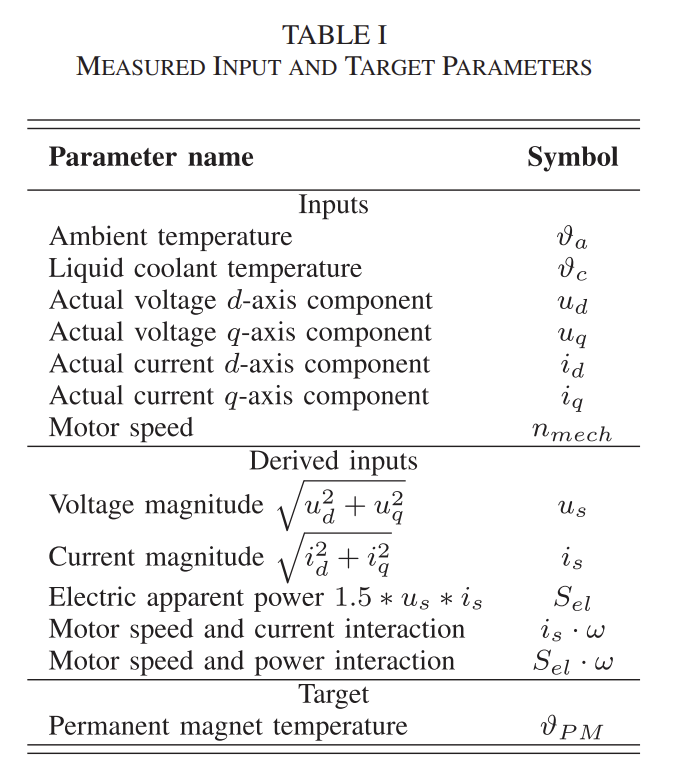

In [3]:
profile_summary = (
    df.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max")
    )
    .reset_index()
)

profile_summary["duration_hours"] = (
    profile_summary["observations"] / (2 * 3600)
)

display(profile_summary)

,profile_id,observations,pm_min,pm_max,duration_hours
0,2,19357,22.970417,45.985561,2.688472
1,3,19248,22.751144,29.011612,2.673333
2,4,33424,22.924950,99.396629,4.642222
3,5,14788,25.889381,39.938965,2.053889
4,6,40388,24.349821,93.512962,5.609444
...,...,...,...,...,...
64,76,22188,31.433067,82.554532,3.081667
65,78,8445,21.266710,68.029359,1.172917
66,79,31154,25.551253,97.153271,4.326944
67,80,23824,23.271483,81.760593,3.308889


## 2.3 Data Quality Assesment
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:

- **Missing values:** No missing values were identified across the 13 columns.
- **Duplicate observations:** No fully duplicated rows were identified.
- **Profile continuity:** All 69 measurement profiles appeared as individual continuous blocks within the dataset.
- **Recording duration:** Profile durations were estimated using the documented 2 Hz sampling frequency.
- **Temperature coverage:** Individual profiles exhibited different minimum and maximum permanent-magnet temperatures.



In [4]:
# Identify consecutive blocks of profile IDs
blocks = df["profile_id"].ne(
    df["profile_id"].shift()
).cumsum()

# Count distinct continuous blocks
n_blocks = blocks.nunique()
n_profiles = df["profile_id"].nunique()

print("Measurement profiles:", n_profiles)
print("Continuous blocks:", n_blocks)

if n_blocks == n_profiles:
    print("PASS: Each profile appears in one continuous block.")
else:
    print("CHECK: Some profiles may appear in multiple blocks.")

# Check missing values and duplicate rows
print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Measurement profiles: 69
Continuous blocks: 69
PASS: Each profile appears in one continuous block.

Missing values:
u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64

Duplicate rows:
0


These results indicate that the dataset is suitable for further preprocessing and supervised regression modelling. However, the preliminary checks do not establish that all measurements are physically plausible or free from sensor errors. Since the dataset does not contain an explicit timestamp column, elapsed time within each profile can be reconstructed from sample position and the documented sampling interval, provided the original ordering is preserved.

## 2.4 Data Splitting Method
An initial 80/20 row-based partition was investigated. However, this approach divided recording profile 65 between the development and final test sets, meaning that observations from the same continuous motor-testing session appeared in both partitions.This was considered inappropriate for the intended evaluation objective: determining whether the estimator can generalise to previously unseen motor operating sessions.


In [5]:
cutoff = int(len(df) * 0.80)

train = df.iloc[:cutoff]
test = df.iloc[cutoff:]

shared_profiles = (
    set(train["profile_id"])
    & set(test["profile_id"])
)

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Profiles appearing in both:", shared_profiles)

Training rows: 1064652
Testing rows: 266164
Profiles appearing in both: {65}


Consequently, a profile-grouped partitioning strategy was adopted, following the grouping principle applied by Kirchgässner et al. (2021).To maintain temperature-condition coverage, profiles were divided into three groups according to their maximum recorded permanent-magnet temperature. A stratified split was then performed using a fixed random seed of 42.


In [6]:

import pandas as pd
from sklearn.model_selection import train_test_split

# STEP 4A: Summarise each measurement profile
profile_table = (
    df.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max"),
        pm_mean=("pm", "mean")
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# STEP 4B: Stratify profiles by maximum PM temperature
# Three approximately equal-sized temperature groups
profile_table["temperature_group"] = pd.qcut(
    profile_table["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# STEP 4C: Split complete profiles, NOT individual rows
train_ids, test_ids = train_test_split(
    profile_table["profile_id"],
    test_size=0.20,
    random_state=42,
    stratify=profile_table["temperature_group"]
)

train_ids = sorted(train_ids.tolist())
test_ids = sorted(test_ids.tolist())

# STEP 4D: Create development and final test datasets
train_df = df[df["profile_id"].isin(train_ids)].copy()
test_df = df[df["profile_id"].isin(test_ids)].copy()

# STEP 4E: Verify no profile overlap
assert set(train_ids).isdisjoint(set(test_ids))
assert len(train_df) + len(test_df) == len(df)

print("Development profiles:", len(train_ids))
print("Test profiles:", len(test_ids))
print("Development observations:", len(train_df))
print("Test observations:", len(test_df))

print("\nActual proportions:")
print(f"Development: {len(train_df)/len(df)*100:.2f}%")
print(f"Final test:  {len(test_df)/len(df)*100:.2f}%")

print("\nFinal test profile IDs:", test_ids)
print("Profile overlap:", set(train_ids) & set(test_ids))



Development profiles: 55
Test profiles: 14
Development observations: 1055198
Test observations: 275618

Actual proportions:
Development: 79.29%
Final test:  20.71%

Final test profile IDs: [13, 16, 23, 24, 29, 42, 44, 47, 53, 56, 62, 67, 71, 78]
Profile overlap: set()


In [7]:

# Assign split labels to profiles
profile_table["split"] = profile_table["profile_id"].apply(
    lambda pid: "Test" if pid in test_ids else "Development"
)

# Count low/medium/high temperature profiles in each set
print("Temperature-group distribution:")
display(
    pd.crosstab(
        profile_table["split"],
        profile_table["temperature_group"]
    )
)

# Compare measurement coverage
for name, data in [("Development", train_df), ("Test", test_df)]:
    print(f"\n{name} set:")
    print("Profiles:", data["profile_id"].nunique())
    print("PM range (°C):", data["pm"].min(), "to", data["pm"].max())
    print("Motor speed range:", data["motor_speed"].min(),
          "to", data["motor_speed"].max())
    print("Torque range:", data["torque"].min(),
          "to", data["torque"].max())

# Save profile assignments for reproducibility
profile_table.to_csv("profile_split.csv", index=False)


Temperature-group distribution:


temperature_group,Low,Medium,High
split,,,
Development,18,18,19
Test,5,5,4



Development set:
Profiles: 55
PM range (°C): 20.856956481933597 to 109.33384704589844
Motor speed range: -275.54914411131955 to 6000.01513671875
Torque range: -246.0862033395314 to 261.0057067871094

Test set:
Profiles: 14
PM range (°C): 21.032411575317383 to 113.60662841796876
Motor speed range: -0.0191213488578796 to 5981.344042117183
Torque range: -246.46666318909087 to 260.83477783203125



| Property | Development Set | Final Test Set |
|:---|:---:|:---:|
| Measurement Profiles | 55 | 14 |
| Observations | 1,055,198 | 275,618 |
| Dataset Proportion | 79.29% | 20.71% |
| Recording Duration | 146.56 h | 38.28 h |
| Low-temperature profiles | 18 | 5 |
| Medium-temperature profiles | 18 | 5 |
| High-temperature profiles | 19 | 4 |

The absence of overlapping profile identifiers was verified programmatically. The achieved proportions differ slightly from the targeted 80/20 division because complete recording sessions were preserved. The approximately 20% test allocation was selected as a practical holdout size consistent with the evaluation approach demonstrated in the MMA3001 teaching material, while retaining sufficient development observations for model training and cross-validation. It is an adaptation rather than an exact reproduction of the original paper's seven-hour holdout.

The selected test profiles will remain excluded from model fitting and hyperparameter optimisation. Within the development set, stratified grouped three-fold cross-validation will be implemented for model selection and optimisation. The same profile assignments will subsequently be used to evaluate the effects of reducing the estimator's sampling frequency, ensuring consistent comparisons between the original and modified computational approaches.


## 2.5 Scope and Limitations
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:


# 3 Computational Solution



## 3.1 Temporal Feature Engineering

Following the methodology of Kirchgässner et al. (2021), exponentially weighted moving averages (EWMA) and exponentially weighted moving standard deviations (EWMS) were implemented to incorporate the historical behaviour of motor operating conditions into the machine-learning inputs.

This feature engineering is necessary because permanent-magnet temperature depends on both current and previous motor operation. Conventional regression models, including ordinary least squares (OLS), do not explicitly maintain a history of previous observations. EWMA and EWMS provide historical information through additional predictor variables.

The EWMA was calculated using:

$$
\mu_t = \frac{\sum_{i=0}^{t} w_i x_{t-i}}{\sum_{i=0}^{t} w_i}
$$

where the weighting factor and smoothing parameter are defined as:

$$
w_i = (1-\alpha)^i, \qquad \alpha = \frac{2}{s+1}
$$

Here, $x_t$ represents the sensor measurement at time $t$, $\alpha$ controls the weighting of historical observations, and $s$ represents the smoothing span.

Larger spans preserve the influence of older measurements for longer, while smaller spans respond more rapidly to changes in motor operating conditions.


In [8]:

import numpy as np
import pandas as pd

def make_paper_inputs(data):
    """Construct the 12 PMSM inputs from Table I of the paper."""

    X = pd.DataFrame(index=data.index)

    # Seven measured inputs
    X["theta_a"] = data["ambient"]
    X["theta_c"] = data["coolant"]
    X["u_d"] = data["u_d"]
    X["u_q"] = data["u_q"]
    X["i_d"] = data["i_d"]
    X["i_q"] = data["i_q"]
    X["n_mech"] = data["motor_speed"]

    # Five derived inputs
    X["u_s"] = np.hypot(X["u_d"], X["u_q"])
    X["i_s"] = np.hypot(X["i_d"], X["i_q"])

    # Apparent electrical power
    X["S_el"] = 1.5 * X["u_s"] * X["i_s"]

    # Angular speed in rad/s
    omega = 2 * np.pi * X["n_mech"] / 60

    X["i_s_omega"] = X["i_s"] * omega
    X["S_el_omega"] = X["S_el"] * omega

    return X



## 3.2 Python Implementation

The computational implementation was developed in Python using Pandas and NumPy.

First, twelve predictor variables were constructed from seven measured quantities and five derived quantities, following Table I of Kirchgässner et al. (2021).

A reusable function `make_temporal_features()` was then developed to generate EWMA and EWMS features for each predictor variable and smoothing span.

Four illustrative spans of 10, 50, 200 and 1,000 samples were initially selected to verify the implementation. These values were selected to demonstrate different smoothing timescales and do not represent optimised hyperparameters.

The resulting feature matrix consisted of:

| Feature category | Number |
|:-----------------|-------:|
| Original measured and derived predictors | 12 |
| EWMA features | 48 |
| EWMS features | 48 |
| **Total predictor variables** | **108** |


In [9]:

def make_temporal_features(X, profile_ids, spans):
    # Calculate temporal features independently per profile
    features = {}

    for column in X.columns:
        grouped = X[column].groupby(
            profile_ids, sort=False
        )

        for span in spans:
            features[f"{column}_ewma_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span, adjust=True
                    ).mean()
                )
            )

            features[f"{column}_ewms_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span, adjust=True
                    ).std(bias=True)
                )
            )

    return pd.concat(
        [X, pd.DataFrame(features, index=X.index)],
        axis=1
    )


In [10]:

# Test 1: Compare EWMA/EWMS against manual calculations

signal = np.array([10.0, 20.0, 30.0])
span = 3
alpha = 2 / (span + 1)

weights = (1 - alpha) ** np.arange(2, -1, -1)

manual_mean = np.sum(weights * signal) / weights.sum()

manual_std = np.sqrt(
    np.sum(weights * (signal - manual_mean)**2)
    / weights.sum()
)

pandas_ewm = pd.Series(signal).ewm(
    span=span, adjust=True
)

np.testing.assert_allclose(
    pandas_ewm.mean().iloc[-1], manual_mean
)

np.testing.assert_allclose(
    pandas_ewm.std(bias=True).iloc[-1],
    manual_std
)

print("PASS: EWMA/EWMS mathematical verification")
print("Manual EWMA:", manual_mean)
print("Manual EWMS:", manual_std)


# Test 2: Check that memory resets between profiles

toy_X = pd.DataFrame({
    "sensor": [10., 20., 30., 100., 100.]
})

toy_ids = pd.Series([1, 1, 1, 2, 2])

toy_features = make_temporal_features(
    toy_X, toy_ids, spans=[3]
)

assert toy_features.loc[3, "sensor_ewma_s3"] == 100.
assert toy_features.loc[3, "sensor_ewms_s3"] == 0.

print("PASS: Profile memory reset")


# Test 3: Verify that future values do not affect past features

modified_X = toy_X.copy()
modified_X.loc[2, "sensor"] = 100000.

modified_features = make_temporal_features(
    modified_X, toy_ids, spans=[3]
)

np.testing.assert_allclose(
    toy_features.loc[:1, "sensor_ewma_s3"],
    modified_features.loc[:1, "sensor_ewma_s3"]
)

print("PASS: No future-data leakage")


PASS: EWMA/EWMS mathematical verification
Manual EWMA: 24.285714285714285
Manual EWMS: 7.2843135908468355
PASS: Profile memory reset
PASS: No future-data leakage



## 3.3 Numerical and Real-Data Verification

Verification was performed before proceeding to machine-learning model training.

Initially, EWMA and EWMS calculations were compared against manually evaluated results using a synthetic signal of (10, 20, 30) and a smoothing span of 3. The manually calculated values agreed with the Pandas implementation within numerical tolerance.

Additional tests confirmed that temporal memory restarted at profile boundaries and that changing a future observation did not affect earlier EWMA results.

The implementation was subsequently tested using actual PMSM measurements. The first 300 observations from each of two development profiles (IDs 2 and 3) were selected, representing 600 observations across two independent sessions.

Four illustrative spans were applied to each of the twelve predictors, generating the expected 108-feature matrix.

**Table X. Real-data feature-engineering verification results.**

| Verification criterion | Result |
|:-----------------------|:-------|
| Measurement profiles | 2 |
| Observations | 600 |
| Original predictor variables | 12 |
| Generated predictor variables | 108 |
| Missing feature values | 0 |
| Non-finite feature values | 0 |
| Feature-dimension verification | Passed |
| Profile-initialisation verification | Passed |

The results confirmed that the feature-engineering pipeline produced the expected dimensions and numerically valid outputs for the selected real-data samples.

In [11]:

# Select two development profiles only
demo_ids = train_ids[:2]

demo_df = (
    train_df[train_df["profile_id"].isin(demo_ids)]
    .groupby("profile_id", sort=False)
    .head(300)
    .copy()
)

# Construct the twelve input variables
X_demo = make_paper_inputs(demo_df)

# Illustrative spans (NOT yet optimised)
example_spans = [10, 50, 200, 1000]

# Generate temporal features
X_temporal = make_temporal_features(
    X_demo,
    demo_df["profile_id"],
    spans=example_spans
)

# Verify feature matrix
assert X_temporal.shape[1] == 108
assert X_temporal.isna().sum().sum() == 0
assert np.isfinite(X_temporal.to_numpy()).all()

print("Profiles:", demo_df["profile_id"].nunique())
print("Original inputs:", X_demo.shape[1])
print("Total features:", X_temporal.shape[1])
print("Missing values:", X_temporal.isna().sum().sum())

display(X_temporal.iloc[:5, :16])


Profiles: 2
Original inputs: 12
Total features: 108
Missing values: 0


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


## 3.4 Visual Verification of EWMA Behaviour

The implementation was further assessed by plotting the q-axis motor current against its exponentially weighted moving averages for measurement Profile 2.

Four illustrative spans of 10, 50, 200 and 1,000 samples were evaluated over the first 150 seconds of the recording.

The results demonstrated that smaller spans responded more rapidly to changes in the original current signal, whereas larger spans produced slower and more heavily smoothed responses.

Figure X. Raw q-axis current and corresponding EWMA responses for four smoothing spans in PMSM measurement Profile 2.

The observed behaviour was consistent with the expected mathematical characteristics of exponential smoothing and provided qualitative evidence supporting the implementation.

However, the numerical and visual verification results do not establish whether the selected temporal features improve permanent-magnet temperature prediction. Furthermore, the implementation uses a weighted standard deviation for EWMS, while Equation (4) of Kirchgässner et al. (2021) contains an ambiguity concerning the variance and standard-deviation convention.

The selection of optimal spans and the quantitative assessment of temperature-prediction accuracy will therefore be conducted during subsequent Bayesian optimisation and grouped cross-validation.

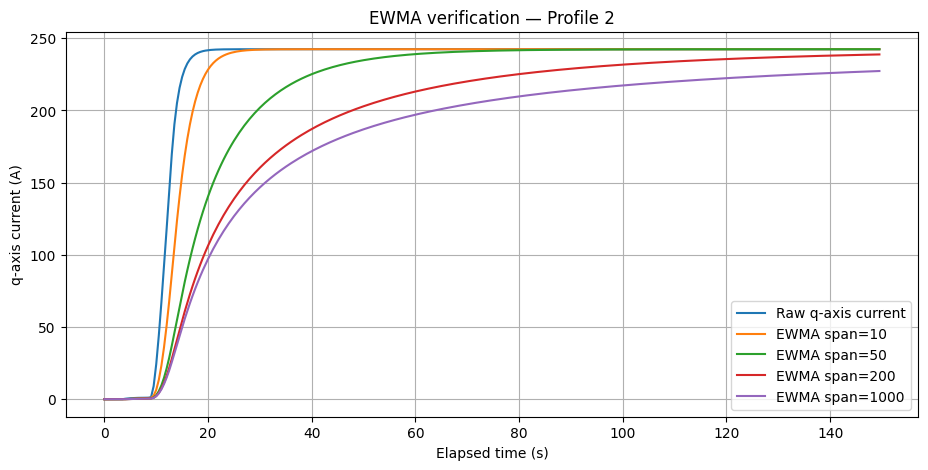

In [12]:

import matplotlib.pyplot as plt

# Examine one measurement profile
pid = demo_ids[0]

mask = demo_df["profile_id"] == pid
time = np.arange(mask.sum()) / 2  # Seconds at 2 Hz

plt.figure(figsize=(11, 5))

plt.plot(
    time,
    X_temporal.loc[mask, "i_q"].to_numpy(),
    label="Raw q-axis current"
)

for span in [10, 50, 200,1000]:
    plt.plot(
        time,
        X_temporal.loc[
            mask, f"i_q_ewma_s{span}"
        ].to_numpy(),
        label=f"EWMA span={span}"
    )

plt.xlabel("Elapsed time (s)")
plt.ylabel("q-axis current (A)")
plt.title(f"EWMA verification — Profile {pid}")
plt.legend()
plt.grid(True)
plt.show()


## 4. Implementation of Stratified Grouped 3-Fold Cross-Validation

## 4.1 Implementation of Stratified Grouped 3-Fold Cross-Validation
Following the feature-engineering verification, stratified grouped three-fold cross-validation was implemented to establish a consistent methodology for evaluating the regression models and their hyperparameters.

The previously established development/test partition was restored using the dataset downloaded through KaggleHub. The development partition consisted of 55 measurement profiles containing 1,055,198 observations, while the final test partition contained 14 profiles with 275,618 observations. The final test partition was reserved for subsequent model evaluation and excluded from cross-validation and hyperparameter optimisation.

A profile-level summary was constructed to calculate the number of observations and minimum and maximum permanent-magnet temperatures for each development profile. The profiles were then classified into three temperature groups: Low, Medium and High using the maximum recorded permanent-magnet temperature as the stratification criterion.

The StratifiedKFold method from Scikit-learn was applied to this profile-level summary using three folds, random shuffling and a fixed random seed of 42. This approach follows the principle of temperature-stratified profile-based validation adopted by Kirchgässner et al. (2021).

Importantly, the folds were constructed from complete measurement profiles rather than individual observations. This prevented measurements belonging to the same recording session from appearing simultaneously in the training and validation subsets of a given cross-validation iteration.

The implementation included assertions to verify the correct development/test partition sizes, complete fold assignment and absence of profile overlap. The resulting fold assignments were saved to profile_cv_assignments.csv for reproducibility.

In [13]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold

# =====================================================
# STEP 6.1A — Restore the existing development/test split
# =====================================================

# df is already loaded from KaggleHub

test_ids = [
    13, 16, 23, 24, 29, 42, 44,
    47, 53, 56, 62, 67, 71, 78
]

train_df = df[
    ~df["profile_id"].isin(test_ids)
].copy()

test_df = df[
    df["profile_id"].isin(test_ids)
].copy()

# Verify the previously established partition
assert len(df) == 1330816
assert len(train_df) == 1055198
assert len(test_df) == 275618
assert set(train_df["profile_id"]).isdisjoint(
    set(test_df["profile_id"])
)

print("PASS: Development/test split restored")


# =====================================================
# STEP 6.1B — Summarise development profiles
# =====================================================

profile_cv = (
    train_df.groupby("profile_id")["pm"]
    .agg(
        observations="size",
        pm_min="min",
        pm_max="max"
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# Create three temperature categories based
# on each profile's maximum PM temperature
profile_cv["temperature_group"] = pd.qcut(
    profile_cv["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)


# =====================================================
# STEP 6.1C — Construct three stratified folds
# =====================================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

profile_cv["cv_fold"] = -1

for fold, (_, val_indices) in enumerate(
    skf.split(
        profile_cv[["pm_max"]],
        profile_cv["temperature_group"]
    ),
    start=1
):
    profile_cv.loc[val_indices, "cv_fold"] = fold

print("PASS: Three validation folds created")


# =====================================================
# STEP 6.1D — Verify profile separation
# =====================================================

development_ids = set(profile_cv["profile_id"])

assert len(development_ids) == 55
assert profile_cv["cv_fold"].isin([1, 2, 3]).all()
assert development_ids.isdisjoint(set(test_ids))

for fold in [1, 2, 3]:

    val_ids = set(
        profile_cv.loc[
            profile_cv["cv_fold"] == fold,
            "profile_id"
        ]
    )

    fold_train_ids = development_ids - val_ids

    assert val_ids.isdisjoint(fold_train_ids)
    assert val_ids.isdisjoint(set(test_ids))

    print(f"\nFold {fold}")
    print("Training profiles:", len(fold_train_ids))
    print("Validation profiles:", len(val_ids))

print("\nPASS: No profile leakage detected")

# Save assignments for reproducibility
profile_cv.to_csv(
    "profile_cv_assignments.csv",
    index=False
)

print("Saved: profile_cv_assignments.csv")


PASS: Development/test split restored
PASS: Three validation folds created

Fold 1
Training profiles: 36
Validation profiles: 19

Fold 2
Training profiles: 37
Validation profiles: 18

Fold 3
Training profiles: 37
Validation profiles: 18

PASS: No profile leakage detected
Saved: profile_cv_assignments.csv


## 4.2 Verification of Cross-Validation Fold Distribution



The resulting cross-validation partitions were examined to verify their distribution across the three temperature groups and the total number of observations assigned to each fold.

**Table 4.1. Distribution of measurement profiles across temperature groups.**

| Validation fold | Low | Medium | High | Total profiles |
|:----------------|----:|-------:|-----:|---------------:|
| Fold 1 | 7 | 6 | 6 | 19 |
| Fold 2 | 6 | 5 | 7 | 18 |
| Fold 3 | 6 | 6 | 6 | 18 |
| **Total** | **19** | **17** | **19** | **55** |

The results demonstrate that each validation fold contained a reasonably balanced representation of the three maximum-temperature categories.

**Table 4.2. Validation-fold observation counts and recording durations.**

| Validation fold | Profiles | Observations | Duration (hours) |
|:----------------|---------:|-------------:|-----------------:|
| Fold 1 | 19 | 401,114 | 55.71 |
| Fold 2 | 18 | 362,087 | 50.29 |
| Fold 3 | 18 | 291,997 | 40.56 |
| **Total** | **55** | **1,055,198** | **146.56** |

Although the number of profiles was approximately balanced, the observation counts differed because individual recording sessions had different durations. This was retained to preserve complete profiles and prevent information leakage.

The verification assertions confirmed that all development observations were assigned to exactly one validation fold, with no overlap between training and validation profile IDs. The reserved final test profiles remained excluded.

During subsequent Bayesian optimisation, each proposed model configuration will be evaluated using all three folds. Its objective value will be the arithmetic mean of the three validation mean squared errors:

$$
\mathrm{MSE}_{\mathrm{CV}} = \frac{\mathrm{MSE}_1 + \mathrm{MSE}_2 + \mathrm{MSE}_3}{3}
$$

Using identical, fixed cross-validation assignments for all regression models ensures a consistent basis for comparing their proposed configurations.


In [14]:

# =====================================================
# STEP 6.1E — Verify temperature-group distribution
# =====================================================

print("Temperature-group distribution:")

display(
    pd.crosstab(
        profile_cv["cv_fold"],
        profile_cv["temperature_group"]
    )
)


# =====================================================
# STEP 6.1F — Verify fold sizes and coverage
# =====================================================

fold_summary = (
    profile_cv.groupby("cv_fold")
    .agg(
        profiles=("profile_id", "size"),
        observations=("observations", "sum"),
        min_pm=("pm_min", "min"),
        max_pm=("pm_max", "max")
    )
)

# The original dataset is sampled at 2 Hz
fold_summary["duration_hours"] = (
    fold_summary["observations"] / 7200
)

print("\nValidation-fold summary:")
display(fold_summary)

# Confirm that every development observation is assigned
assert fold_summary["observations"].sum() == len(train_df)
assert fold_summary["profiles"].sum() == 55

print("\nPASS: All development observations assigned")


Temperature-group distribution:


temperature_group,Low,Medium,High
cv_fold,,,
1,7,6,6
2,6,5,7
3,6,6,6



Validation-fold summary:


,profiles,observations,min_pm,max_pm,duration_hours
cv_fold,,,,,
1,19,401114,21.213623,109.333847,55.710278
2,18,362087,20.856956,105.948723,50.289861
3,18,291997,22.888792,99.396629,40.555139



PASS: All development observations assigned


## 4.3 Preliminary Verification of Regression Model Pipelines

Before conducting computationally expensive Bayesian optimisation, preliminary regression-training pipelines were implemented to verify compatibility between the engineered temporal features, the regression algorithms and the grouped validation methodology.

Six regression models investigated by Kirchgässner et al. (2021) were considered: Ordinary Least Squares (OLS), Support Vector Regression (SVR), k-Nearest Neighbours (k-NN), Random Forest, Extra Trees and Multi-Layer Perceptron (MLP).

In [15]:

import numpy as np
import pandas as pd

# =====================================================
# STEP 6.2A — Prepare a small development-data sample
# =====================================================

# These are example spans, not optimised values.
SMOKE_SPANS = [10, 50, 200, 1000]
SAMPLES_PER_PROFILE = 80

def make_pipeline_test_data(data, spans, samples_per_profile=80):
    """
    Create a small dataset to verify ML training pipelines.

    EWMA/EWMS is calculated using the full 2-Hz history
    of each profile before selecting training observations.
    """
    sampled_profiles = []

    for pid, profile in data.groupby(
        "profile_id", sort=False
    ):
        # Construct the 12 original input variables
        X = make_paper_inputs(profile)

        # Calculate temporal features from full history
        X_full = make_temporal_features(
            X, profile["profile_id"], spans
        )

        # Select representative positions across this profile
        n = min(samples_per_profile, len(profile))

        positions = np.linspace(
            0, len(profile) - 1, n, dtype=int
        )

        sample = X_full.iloc[positions].copy()

        # Target is stored separately from predictors
        sample["pm_target"] = (
            profile["pm"].iloc[positions].to_numpy()
        )
        sample["profile_id"] = pid

        sampled_profiles.append(sample)

    return pd.concat(
        sampled_profiles, ignore_index=True
    )


smoke_df = make_pipeline_test_data(
    train_df,
    SMOKE_SPANS,
    samples_per_profile=SAMPLES_PER_PROFILE
)

# Verification
assert smoke_df["profile_id"].nunique() == 55
assert len(smoke_df) == 55 * SAMPLES_PER_PROFILE
assert smoke_df.shape[1] == 110  # 108 + target + profile ID
assert smoke_df.isna().sum().sum() == 0
assert np.isfinite(smoke_df.to_numpy()).all()

print("PASS: Pipeline test dataset prepared")
print("Observations:", len(smoke_df))
print("Predictor features:", smoke_df.shape[1] - 2)
print("Profiles:", smoke_df["profile_id"].nunique())


PASS: Pipeline test dataset prepared
Observations: 4400
Predictor features: 108
Profiles: 55



### 4.3.1 Preparation of the Preliminary Training Dataset

The complete development dataset contained more than one million observations. To reduce computational requirements during initial implementation testing, a smaller dataset was constructed by selecting 80 observations distributed across each of the 55 development profiles.

Importantly, the EWMA/EWMS temporal features were calculated using each profile's complete original 2 Hz measurement history before selecting the observations. This ensured that the selected features retained information from the preceding measurements rather than being calculated from an artificially shortened history.

Four illustrative spans of 10, 50, 200 and 1,000 samples were used, consistent with the earlier feature-engineering verification. These were fixed demonstration settings, not optimised hyperparameters.

**Table 4.3. Preliminary regression dataset characteristics.**

| Characteristic | Result |
|:---------------|-------:|
| Development profiles represented | 55 |
| Selected observations per profile | 80 |
| Total observations | 4,400 |
| Predictor variables | 108 |
| Prediction target | Permanent-magnet temperature (`pm`) |
| Missing feature values | 0 |

The resulting dataset passed the dimensional and numerical-validity checks and was used exclusively for preliminary model-pipeline verification.


In [16]:

import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# =====================================================
# STEP 6.2B — Select the first grouped CV fold
# =====================================================

val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

train_sample = smoke_df[
    ~smoke_df["profile_id"].isin(val_ids)
].copy()

val_sample = smoke_df[
    smoke_df["profile_id"].isin(val_ids)
].copy()

# Separate inputs and target
feature_cols = [
    c for c in smoke_df.columns
    if c not in ["pm_target", "profile_id"]
]

X_train = train_sample[feature_cols]
y_train = train_sample["pm_target"]

X_val = val_sample[feature_cols]
y_val = val_sample["pm_target"]

# Verify no profile overlap
assert set(train_sample["profile_id"]).isdisjoint(
    set(val_sample["profile_id"])
)

assert len(feature_cols) == 108

print("Training profiles:",
      train_sample["profile_id"].nunique())
print("Validation profiles:",
      val_sample["profile_id"].nunique())


# =====================================================
# STEP 6.2C — Define the six regression models
# =====================================================

models = {
    "OLS": LinearRegression(),

    "SVR": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),

    "k-NN": KNeighborsRegressor(
        n_neighbors=10,
        weights="distance"
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=20,
        max_depth=12,
        random_state=42,
        n_jobs=2
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=20,
        max_depth=12,
        random_state=42,
        n_jobs=2
    ),

    "MLP": MLPRegressor(
        hidden_layer_sizes=(32,),
        max_iter=150,
        random_state=42
    )
}


# =====================================================
# STEP 6.2D — Train, predict and evaluate each model
# =====================================================

results = []

for name, estimator in models.items():

    # StandardScaler is fitted on TRAINING data only.
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    # Train
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    # Predict on unseen validation profiles
    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    # Calculate prediction errors
    errors = y_val.to_numpy() - predictions

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "MAE": mean_absolute_error(y_val, predictions),
        "R2": r2_score(y_val, predictions),
        "Max Error": np.max(np.abs(errors)),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    })

    print(f"PASS: {name} trained and evaluated")

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))

# Save preliminary results
results_df.to_csv(
    "model_pipeline_smoke_test.csv",
    index=False
)

print("\nPASS: All six regression pipelines completed")


Training profiles: 36
Validation profiles: 19
PASS: OLS trained and evaluated
PASS: SVR trained and evaluated
PASS: k-NN trained and evaluated
PASS: Random Forest trained and evaluated
PASS: Extra Trees trained and evaluated
PASS: MLP trained and evaluated


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,MSE,RMSE,MAE,R2,Max Error,Training Time (s),Inference Time (s)
0,OLS,88.6563,9.4157,6.3003,0.7667,213.7320,0.1044,0.0095
1,SVR,84.9066,9.2145,6.7282,0.7766,41.8656,1.7565,1.1446
2,k-NN,87.2593,9.3413,7.0180,0.7704,45.0894,0.0104,0.1144
3,Random Forest,94.2754,9.7096,7.5968,0.7520,42.8915,6.7906,0.0167
4,Extra Trees,57.5839,7.5884,5.7671,0.8485,35.3301,1.0185,0.0169
5,MLP,86.6788,9.3101,7.1344,0.7719,50.7575,2.3338,0.0080



PASS: All six regression pipelines completed



## 4.4 Preliminary OLS Error Investigation

Inspection of the initial model-comparison results identified an unusually large maximum absolute prediction error for OLS. A dedicated diagnostic procedure was therefore implemented to determine which observations contributed most strongly to its validation error.

The OLS pipeline was retrained using the same preliminary training and validation partition. A diagnostic table was constructed containing the measurement profile ID, measured permanent-magnet temperature, predicted temperature and absolute prediction error. The observations were then ranked by descending absolute error.

The largest prediction error was identified in measurement profile 65.

**Table 4.4. Largest OLS prediction error.**

| Quantity | Value |
|:---------|------:|
| Measurement profile | 65 |
| Actual permanent-magnet temperature | 26.04 °C |
| OLS-predicted temperature | 239.77 °C |
| Absolute prediction error | 213.73 °C |

The next-largest absolute error was approximately 38.19 °C, considerably smaller than the error observed in profile 65.

This result indicated that the maximum error was dominated by an exceptionally poor prediction rather than being representative of the model's general prediction accuracy. However, the initial diagnostic could not establish whether the discrepancy originated from a measurement anomaly, unusual predictor values or instability in the fitted regression model.

Consequently, further investigation was conducted before considering any modification to the dataset.


In [17]:

# STEP 6.2E — Investigate OLS prediction outliers

ols_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ols_pipeline.fit(X_train, y_train)

ols_predictions = ols_pipeline.predict(X_val)

ols_diagnostics = pd.DataFrame({
    "profile_id": val_sample["profile_id"].to_numpy(),
    "actual_pm": y_val.to_numpy(),
    "predicted_pm": ols_predictions
})

ols_diagnostics["absolute_error"] = abs(
    ols_diagnostics["actual_pm"]
    - ols_diagnostics["predicted_pm"]
)

print("Ten largest OLS prediction errors:")

display(
    ols_diagnostics.nlargest(
        10, "absolute_error"
    )
)

print(
    "\nMeasured PM temperature range:",
    y_val.min(), "to", y_val.max()
)

print(
    "Predicted PM temperature range:",
    ols_predictions.min(),
    "to",
    ols_predictions.max()
)

print(
    "Maximum absolute error:",
    ols_diagnostics["absolute_error"].max()
)


Ten largest OLS prediction errors:


,profile_id,actual_pm,predicted_pm,absolute_error
1280,65,26.037928,239.769930,213.732002
1201,72,41.780465,79.972030,38.191565
641,15,31.670839,63.268627,31.597788
642,15,41.445896,67.217468,25.771572
474,27,75.651138,50.344875,25.306263
473,27,82.210464,57.981359,24.229105
1122,69,29.539304,53.191581,23.652277
475,27,70.167656,46.599690,23.567966
869,75,68.704834,46.433088,22.271746
1121,69,27.300511,49.327319,22.026808



Measured PM temperature range: 21.222400665283203 to 108.76202392578124
Predicted PM temperature range: 13.65591504531919 to 239.76992950006118
Maximum absolute error: 213.73200170283144



## 4.5 Investigation of Profile-Start Prediction Errors

A subsequent diagnostic examined whether the extreme OLS prediction occurred near the beginning of a measurement profile, where the exponentially weighted temporal features contain limited historical information.

Each observation in the validation diagnostic table was assigned a position within its corresponding profile. The largest prediction errors were then examined alongside their relative sample positions.

The investigation confirmed that the 213.73 °C prediction error occurred at position zero—the first recorded observation of profile 65.

At the first measurement of a profile, the exponentially weighted moving average is equal to the initial sensor measurement, while the exponentially weighted standard deviation is zero under the implemented biased weighted-variance convention. Consequently, the temporal features are initially less informative about the motor's preceding operating conditions.

The first five selected observations of profile 65 were inspected to examine how prediction error changed as additional measurement history became available.

**Table 4.5. Initial sampled observations of profile 65.**

| Sample position | Actual PM (°C) | Predicted PM (°C) | Absolute error (°C) |
|:----------------|---------------:|------------------:|--------------------:|
| 0 | 26.04 | 239.77 | 213.73 |
| 1 | 35.64 | 49.01 | 13.36 |
| 2 | 40.72 | 47.19 | 6.46 |
| 3 | 53.52 | 62.60 | 9.08 |
| 4 | 61.69 | 67.20 | 5.51 |

The error decreased substantially after the initial sampled observation, suggesting that the extreme prediction might be associated with a profile-start or cold-start condition.

To investigate whether this pattern extended across the validation set, the mean absolute errors at the first sampled observations of all profiles were compared with those at subsequent sampled observations.

**Table 4.6. Profile-start versus subsequent prediction errors.**

| Observation category | Mean absolute error |
|:---------------------|--------------------:|
| First sampled observations | 18.52 °C |
| Subsequent sampled observations | 6.15 °C |
| First observations excluding profile 65's extreme prediction, for diagnosis only | 7.67 °C |

Although the initial comparison suggested substantially higher errors at profile starts, the sensitivity comparison demonstrated that the extreme profile-65 prediction strongly influenced this result.

Therefore, the findings support investigating EWMA/EWMS initialisation as a possible contributing factor, but do not establish it as the sole cause of the prediction error. Highly correlated regression inputs, unusual operating conditions and coefficient instability remain possible explanations.


In [18]:

# STEP 6.2F — Investigate OLS errors at profile starts

# Identify the position of each sampled observation
# within its own validation profile.
ols_diagnostics["position_in_profile"] = (
    ols_diagnostics.groupby("profile_id").cumcount()
)

# Inspect the largest prediction errors
display(
    ols_diagnostics.nlargest(
        10, "absolute_error"
    )
)

# Inspect the first five sampled observations
# from the problematic profile
print("\nFirst five sampled observations of profile 65:")

display(
    ols_diagnostics[
        ols_diagnostics["profile_id"] == 65
    ].head(5)
)

# Compare errors at the first sample versus later samples
first_samples = ols_diagnostics[
    ols_diagnostics["position_in_profile"] == 0
]

later_samples = ols_diagnostics[
    ols_diagnostics["position_in_profile"] > 0
]

print("\nMean absolute error at profile starts:",
      first_samples["absolute_error"].mean())

print("Mean absolute error at later observations:",
      later_samples["absolute_error"].mean())


,profile_id,actual_pm,predicted_pm,absolute_error,position_in_profile
1280,65,26.037928,239.769930,213.732002,0
1201,72,41.780465,79.972030,38.191565,1
641,15,31.670839,63.268627,31.597788,1
642,15,41.445896,67.217468,25.771572,2
474,27,75.651138,50.344875,25.306263,74
473,27,82.210464,57.981359,24.229105,73
1122,69,29.539304,53.191581,23.652277,2
475,27,70.167656,46.599690,23.567966,75
869,75,68.704834,46.433088,22.271746,69
1121,69,27.300511,49.327319,22.026808,1



First five sampled observations of profile 65:


,profile_id,actual_pm,predicted_pm,absolute_error,position_in_profile
1280,65,26.037928,239.769930,213.732002,0
1281,65,35.643693,49.005254,13.361560,1
1282,65,40.722855,47.186275,6.463419,2
1283,65,53.522017,62.603549,9.081532,3
1284,65,61.693861,67.202789,5.508929,4



Mean absolute error at profile starts: 18.51543395268992
Mean absolute error at later observations: 6.1456774940046



## 4.6 OLS Outlier Influence and Sensitivity Analysis

A further diagnostic was implemented to quantify the influence of the extreme prediction on the overall validation mean squared error.

The squared error of each OLS prediction was calculated, and the largest squared error was expressed as a percentage of the total squared validation error.

The first raw measurements of profile 65 were also inspected. The initial recorded permanent-magnet temperature was approximately 26.04 °C, with coolant temperature around 24.57 °C, ambient temperature around 25.16 °C and motor speed around 3,029 rpm.

The resulting influence analysis is summarised below.

**Table 4.7. Sensitivity of preliminary OLS validation error to the extreme prediction.**

| Diagnostic measure | Result |
|:-------------------|-------:|
| Validation observations | 1,520 |
| Largest absolute prediction error | 213.73 °C |
| Contribution to total squared error | 33.9% |
| MSE using all validation observations | 88.66 °C² |
| MSE excluding the largest error for diagnosis only | 58.64 °C² |

A single observation therefore accounted for approximately one-third of the total squared validation error.

The reduced MSE was calculated only to quantify the influence of the extreme prediction. It was not adopted as a replacement performance metric, and the observation was not removed from the original dataset, the validation partition or the subsequent model-development procedure.

The result demonstrates that aggregate MSE can be highly sensitive to isolated extreme predictions and supports the use of additional metrics, such as MAE and maximum absolute error, when evaluating the temperature estimators.

#### Treatment Decision

No evidence was established that the original temperature measurement was invalid. The anomaly was identified in the model's prediction error, rather than confirmed as a defective data point.

Therefore, the observation in profile 65 was retained without modification. Removing difficult-to-predict measurements solely to improve validation accuracy would undermine the credibility of the performance comparison.

The potential causes of the extreme prediction remain open for further investigation, particularly the effect of temporal-feature initialisation and the sensitivity of the OLS coefficients.


In [19]:

# STEP 6.2G — Investigate the extreme prediction

# Examine raw measurements at the start of profile 65
print("First five raw measurements of profile 65:")

display(
    df.loc[df["profile_id"] == 65].head(5)
)

# Quantify influence of the largest error
squared_errors = (
    ols_diagnostics["actual_pm"]
    - ols_diagnostics["predicted_pm"]
) ** 2

worst_idx = squared_errors.idxmax()

outlier_contribution = (
    squared_errors.loc[worst_idx]
    / squared_errors.sum()
    * 100
)

print(
    "\nPercentage of total OLS squared error "
    "from the single largest prediction:",
    round(outlier_contribution, 2), "%"
)

# Diagnostic sensitivity calculation only
print(
    "\nValidation MSE with all observations:",
    squared_errors.mean()
)

print(
    "Validation MSE excluding largest error:",
    squared_errors.drop(worst_idx).mean()
)


First five raw measurements of profile 65:


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
1042494,-0.060301,24.572270,25.328268,-0.044640,24.759084,3028.577653,-16.682717,-22.554878,26.037928,23.902619,25.156664,-5.036988,65
1042495,-0.098472,24.549411,25.332084,-0.087538,24.771273,3277.195135,-32.674103,-36.837572,26.171841,23.906777,25.158406,7.594919,65
1042496,-0.134579,24.529792,25.289755,-0.137843,24.780007,3526.252702,-51.436325,-50.341317,25.995341,23.909756,25.159215,19.732400,65
1042497,-0.163837,24.506268,25.284230,-0.188305,24.786265,3775.622429,-70.247635,-61.302441,25.900132,23.910191,25.157646,27.199507,65
1042498,-0.185884,24.494794,25.343128,-0.235406,24.790749,4025.182345,-87.820645,-69.577852,25.862153,23.911742,25.156261,30.220038,65



Percentage of total OLS squared error from the single largest prediction: 33.9 %

Validation MSE with all observations: 88.65626137696218
Validation MSE excluding largest error: 58.641309243636194


## 4.7 Preliminary Verification Conclusion and Transition to Bayesian Optimisation

The preliminary implementation successfully established stratified grouped three-fold cross-validation and functioning training and evaluation pipelines for all six regression models.

The diagnostic investigation also identified an extreme OLS prediction error at the beginning of measurement profile 65. Although its location suggests potential sensitivity to the initialisation of temporal features, the cause has not yet been conclusively determined. The observation was therefore retained to preserve the original dataset and provide an unbiased basis for subsequent evaluation.

The next stage will implement Bayesian hyperparameter optimisation using the three established validation folds. This process will search for suitable EWMA/EWMS spans and model-specific hyperparameters by minimising average cross-validation MSE.

In addition to evaluating overall prediction accuracy, the optimised OLS model will be examined to determine whether its performance on profile 65 improves relative to the preliminary configuration. This comparison will be treated as exploratory and interpreted with regard to differences in training-data size and model configuration. Improved average cross-validation accuracy does not necessarily guarantee that the specific extreme prediction will improve.

Following optimisation, the selected models will be retrained using all development profiles and evaluated on the untouched final test set to establish the 2 Hz benchmark for the subsequent sampling-frequency investigation.

## 4.8 Bayesian Hyperparameter Optimisation

### 4.8.1 Initial Bayesian Optimisation Pilot

Following preliminary verification of the regression pipelines, Gaussian-process Bayesian optimisation was implemented to select the four exponentially weighted moving average (EWMA) and exponentially weighted moving standard deviation (EWMS) spans used to represent the motor's operating history. Ordinary Least Squares (OLS) was selected for the first pilot because its regression coefficients could be fitted comparatively quickly. The optimisation selected *feature-engineering spans*, rather than directly searching for the OLS regression coefficients; those coefficients were determined during each least-squares fit.

The objective was the arithmetic mean of the validation mean squared errors (MSE) from the previously established stratified grouped three-fold cross-validation:

$$
\mathrm{MSE}_{\mathrm{CV}} = \frac{\mathrm{MSE}_1 + \mathrm{MSE}_2 + \mathrm{MSE}_3}{3}
$$

The three folds preserved complete recording profiles and distributed profiles by maximum permanent-magnet temperature. For computationally manageable pilot evaluations, 80 observations were selected across each of the 55 development profiles, producing 4,400 observations. Importantly, the EWMA/EWMS features were first calculated over each profile's complete 2 Hz time history and only then subsampled. The feature scaler was fitted separately using the training portion of each fold, preventing the validation data from influencing standardisation.

The `scikit-optimize` `gp_minimize` procedure used a Gaussian-process surrogate model with expected improvement as its acquisition function. Eight span configurations were evaluated: four initial random proposals and four subsequent proposals informed by the surrogate. As an implementation check, manually chosen spans of (10, 50, 200, 1000) gave a mean CV MSE of **64.6399 °C²**, with fold errors of 88.6563, 54.8137 and 50.4498 °C².

The initial Bayesian pilot achieved its lowest error at Trial 7 with spans **(30, 150, 652, 3000)** and a mean CV MSE of **45.6467 °C²**. This represented a **29.38% reduction** relative to the fixed-span reference. The pilot established that span selection, temporal-feature engineering, grouped validation, regression fitting and Bayesian proposals could operate as an integrated workflow, but eight evaluations could not establish convergence.

In [20]:

# STEP 6.3A — Bayesian optimisation setup

%pip -q install scikit-optimize

import time
import numpy as np
import pandas as pd

from skopt import gp_minimize
from skopt.space import Integer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Preliminary optimisation settings
SAMPLES_PER_PROFILE = 80
RANDOM_STATE = 42

# Use the exact CV assignments from Step 6.1
fold_lookup = profile_cv.set_index(
    "profile_id"
)["cv_fold"]

assert len(train_df) == 1055198
assert len(fold_lookup) == 55
assert set(fold_lookup.unique()) == {1, 2, 3}


def build_candidate_features(spans):
    """
    Construct features for candidate EWMA/EWMS spans.

    Full original 2-Hz histories are processed before
    selecting 80 observations per development profile.
    """
    feature_arrays = []
    target_arrays = []
    profile_arrays = []

    for pid, profile in train_df.groupby(
        "profile_id", sort=False
    ):

        X_original = make_paper_inputs(profile)

        X_temporal = make_temporal_features(
            X_original,
            profile["profile_id"],
            spans
        )

        n = min(SAMPLES_PER_PROFILE, len(profile))

        positions = np.linspace(
            0, len(profile) - 1, n, dtype=int
        )

        feature_arrays.append(
            X_temporal.iloc[positions].to_numpy(
                dtype=np.float64
            )
        )

        target_arrays.append(
            profile["pm"].iloc[positions].to_numpy()
        )

        profile_arrays.append(
            np.full(n, pid)
        )

    X = np.vstack(feature_arrays)
    y = np.concatenate(target_arrays)
    profile_ids = np.concatenate(profile_arrays)

    assert X.shape[1] == 108
    assert len(X) == 4400
    assert np.isfinite(X).all()

    return X, y, profile_ids


def evaluate_ols_cv(spans):
    """
    Evaluate a four-span configuration with the same
    fixed, grouped, stratified 3-fold CV.

    Return average CV MSE and individual fold scores.
    """
    X, y, profile_ids = build_candidate_features(spans)

    fold_ids = (
        pd.Series(profile_ids)
        .map(fold_lookup)
        .to_numpy(dtype=int)
    )

    fold_mse = []

    for fold in [1, 2, 3]:

        train_mask = fold_ids != fold
        val_mask = fold_ids == fold

        assert train_mask.sum() > 0
        assert val_mask.sum() > 0
        assert set(profile_ids[train_mask]).isdisjoint(
            set(profile_ids[val_mask])
        )

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ])

        pipeline.fit(
            X[train_mask],
            y[train_mask]
        )

        predictions = pipeline.predict(
            X[val_mask]
        )

        mse = mean_squared_error(
            y[val_mask],
            predictions
        )

        fold_mse.append(float(mse))

    return float(np.mean(fold_mse)), fold_mse


print("PASS: Bayesian optimisation objective defined")


PASS: Bayesian optimisation objective defined


### 4.8.2 Review and Expansion of Search Intervals (Step 6.3B)

Reviewing the pilot revealed that several best-performing span values approached or reached the initial upper search boundaries. The search was therefore expanded to permit longer temporal-memory representations. To guarantee increasing spans, the four original span values were reparameterised in terms of an initial span and three positive increments:

$$
\begin{aligned}
s_1&=a,\\
s_2&=a+d_2,\\
s_3&=a+d_2+d_3,\\
s_4&=a+d_2+d_3+d_4.
\end{aligned}
$$

The expanded parameter intervals were $a\in[5,100]$, $d_2\in[1,400]$, $d_3\in[1,1500]$, and $d_4\in[1,6000]$. These constraints enforce $s_1<s_2<s_3<s_4$ while allowing the optimizer to explore a wider range of historical smoothing scales. The eight initial observations, including their measured CV errors, were supplied to the newly parameterised optimiser. Twenty additional configurations were then evaluated, producing a cumulative search of **28 trials**. In the current Run-All notebook, those trials are generated during the active execution rather than restored from an earlier session.

In [21]:

# STEP 6.3B — Verify Bayesian objective function

baseline_spans = [10, 50, 200, 1000]

baseline_mse, baseline_folds = evaluate_ols_cv(
    baseline_spans
)

print("Example spans:", baseline_spans)

for fold, mse in enumerate(baseline_folds, start=1):
    print(f"Fold {fold} MSE: {mse:.4f} °C²")

print(f"\nAverage CV MSE: {baseline_mse:.4f} °C²")

# Verify against the previously observed result
np.testing.assert_allclose(
    baseline_mse,
    64.6399,
    rtol=1e-3
)

print("PASS: OLS CV objective reproduces baseline")


Example spans: [10, 50, 200, 1000]
Fold 1 MSE: 88.6563 °C²
Fold 2 MSE: 54.8137 °C²
Fold 3 MSE: 50.4498 °C²

Average CV MSE: 64.6399 °C²
PASS: OLS CV objective reproduces baseline


In [22]:

# STEP 6.3C — Gaussian-process Bayesian optimisation

search_space = [
    Integer(5, 30, name="span_1"),
    Integer(31, 150, name="span_2"),
    Integer(151, 700, name="span_3"),
    Integer(701, 3000, name="span_4")
]

trial_records = []


def bayesian_objective(candidate):
    """
    Objective minimised by Gaussian-process
    Bayesian optimisation.
    """
    spans = [int(s) for s in candidate]

    start = time.perf_counter()

    mean_mse, fold_scores = evaluate_ols_cv(spans)

    duration = time.perf_counter() - start

    record = {
        "trial": len(trial_records) + 1,
        "s1": spans[0],
        "s2": spans[1],
        "s3": spans[2],
        "s4": spans[3],
        "fold1_mse": fold_scores[0],
        "fold2_mse": fold_scores[1],
        "fold3_mse": fold_scores[2],
        "mean_cv_mse": mean_mse,
        "runtime_s": duration
    }

    trial_records.append(record)

    print(
        f"Trial {record['trial']}: "
        f"spans={spans}, "
        f"CV MSE={mean_mse:.4f}, "
        f"time={duration:.1f}s",
        flush=True
    )

    return mean_mse


# Small initial search to verify optimisation
result = gp_minimize(
    func=bayesian_objective,
    dimensions=search_space,
    n_calls=8,
    n_initial_points=4,
    acq_func="EI",
    random_state=RANDOM_STATE
)

pd.DataFrame(trial_records).to_csv(
    "bayesian_ols_pilot_trials.csv", index=False
)
print("\nPASS: OLS Bayesian optimisation pilot completed")
print("Best spans:", result.x)
print(f"Best CV MSE: {result.fun:.4f} °C²")

display(
    pd.DataFrame(trial_records)
    .sort_values("mean_cv_mse")
    .round(4)
)


Trial 1: spans=[25, 53, 579, 2073], CV MSE=48.3574, time=14.6s
Trial 2: spans=[16, 43, 403, 1468], CV MSE=53.7103, time=14.0s
Trial 3: spans=[9, 108, 182, 2361], CV MSE=48.6122, time=8.8s
Trial 4: spans=[28, 31, 696, 2121], CV MSE=47.8367, time=6.7s
Trial 5: spans=[30, 31, 700, 2347], CV MSE=47.1058, time=6.6s
Trial 6: spans=[30, 31, 700, 3000], CV MSE=45.9508, time=6.6s
Trial 7: spans=[30, 150, 652, 3000], CV MSE=45.6467, time=6.7s
Trial 8: spans=[5, 150, 700, 3000], CV MSE=45.7540, time=6.5s

PASS: OLS Bayesian optimisation pilot completed
Best spans: [np.int64(30), np.int64(150), np.int64(652), np.int64(3000)]
Best CV MSE: 45.6467 °C²


,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,6.7030
7,8,5,150,700,3000,65.9788,36.9979,34.2855,45.7540,6.5088
5,6,30,31,700,3000,66.1333,37.6906,34.0287,45.9508,6.5840
4,5,30,31,700,2347,67.9360,38.8915,34.4900,47.1058,6.5832
3,4,28,31,696,2121,68.9513,39.5925,34.9663,47.8367,6.6522
0,1,25,53,579,2073,69.7459,40.1931,35.1333,48.3574,14.6236
2,3,9,108,182,2361,70.0873,40.4242,35.3250,48.6122,8.7555
1,2,16,43,403,1468,76.3572,44.9916,39.7820,53.7103,14.0037


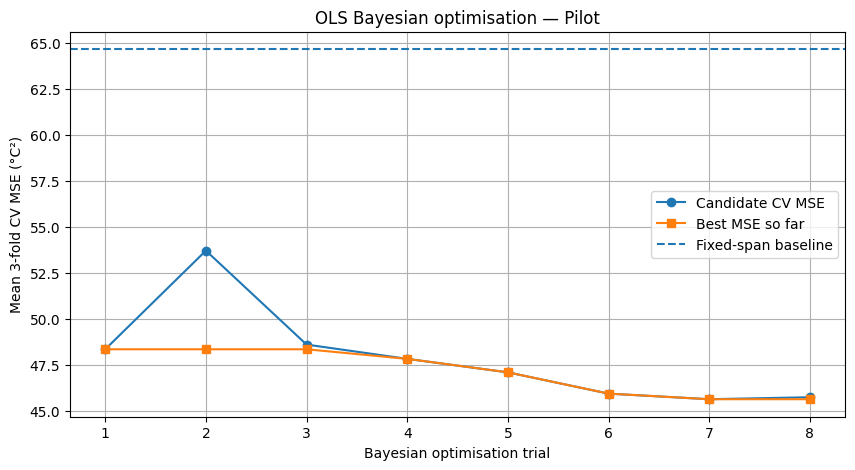

In [23]:

# STEP 6.3D — Visualise Bayesian search progress

import matplotlib.pyplot as plt

history = pd.DataFrame(trial_records)

history["best_so_far"] = (
    history["mean_cv_mse"].cummin()
)

plt.figure(figsize=(10, 5))

plt.plot(
    history["trial"],
    history["mean_cv_mse"],
    "o-",
    label="Candidate CV MSE"
)

plt.plot(
    history["trial"],
    history["best_so_far"],
    "s-",
    label="Best MSE so far"
)

plt.axhline(
    baseline_mse,
    linestyle="--",
    label="Fixed-span baseline"
)

plt.xlabel("Bayesian optimisation trial")
plt.ylabel("Mean 3-fold CV MSE (°C²)")
plt.title("OLS Bayesian optimisation — Pilot")
plt.legend()
plt.grid(True)
plt.show()


### 4.8.2 Review and Expansion of Search Intervals (Step 6.3B)

Inspection of the initial optimisation results revealed that three of the four selected spans reached their respective upper search limits. This suggested that the initial search intervals might constrain the exploration of longer temporal-memory representations.

Consequently, the search space was expanded and reparameterised using the first span and three positive differences between consecutive spans:

$$
\begin{aligned}
s_1 &= a \\
s_2 &= a+d_2 \\
s_3 &= a+d_2+d_3 \\
s_4 &= a+d_2+d_3+d_4
\end{aligned}
$$

This parameterisation guaranteed strictly increasing span values while permitting a wider range of smoothing timescales.

The expanded intervals were 5–100 for the first span, 1–400 for the second-span increment, 1–1,500 for the third-span increment and 1–6,000 for the fourth-span increment.

The original eight evaluated configurations were reused by supplying their recorded objective values to the newly parameterised Gaussian-process optimiser. Twenty additional configurations were then evaluated, producing 28 evaluations in total. Results were checkpointed after each completed trial.

In [24]:

# STEP 6.3B.1 — Expanded Bayesian search setup

import os
import time
import numpy as np
import pandas as pd

from skopt import Optimizer
from skopt.space import Integer

PILOT_PATH = "bayesian_ols_pilot_trials.csv"
EXPANDED_PATH = "bayesian_ols_expanded_trials.csv"

# New search space: first span + three positive gaps
expanded_space = [
    Integer(5, 100, name="s1"),
    Integer(1, 400, name="gap_2"),
    Integer(1, 1500, name="gap_3"),
    Integer(1, 6000, name="gap_4")
]

def decode_spans(parameters):
    """Convert first span and gaps into four ordered spans."""
    a, d2, d3, d4 = map(int, parameters)

    return [
        a,
        a + d2,
        a + d2 + d3,
        a + d2 + d3 + d4
    ]


def encode_spans(spans):
    """Convert four ordered spans into the new search space."""
    a, b, c, d = map(int, spans)

    if not a < b < c < d:
        raise ValueError("Spans must be strictly increasing")

    return [a, b-a, c-b, d-c]


# Previous eight trials are generated earlier in THIS Run All execution.
# Deliberately ignore files from old runtimes.
pilot_df = pd.DataFrame(trial_records).copy()
pilot_df.to_csv(PILOT_PATH, index=False)

assert len(pilot_df) == 8

# Confirm all old trials fit in the expanded space
for _, row in pilot_df.iterrows():
    old_spans = [
        int(row["s1"]), int(row["s2"]),
        int(row["s3"]), int(row["s4"])
    ]

    params = encode_spans(old_spans)

    assert all(
        dimension.low <= value <= dimension.high
        for dimension, value in zip(expanded_space, params)
    )

print("PASS: All eight previous trials are reusable")

print("\nPrevious best configuration:")
best_old = pilot_df.loc[
    pilot_df["mean_cv_mse"].idxmin()
]

print("Spans:", [
    int(best_old[f"s{i}"]) for i in range(1, 5)
])
print("CV MSE:", best_old["mean_cv_mse"])


PASS: All eight previous trials are reusable

Previous best configuration:
Spans: [30, 150, 652, 3000]
CV MSE: 45.646703863447016


In [25]:

# STEP 6.3B.2 — Continue Bayesian optimisation

N_ADDITIONAL_TRIALS = 20

# Always perform a fresh expanded search after the freshly generated pilot.
expanded_df = pd.DataFrame(columns=pilot_df.columns)

# Reconstruct the optimiser from recorded results
optimizer = Optimizer(
    dimensions=expanded_space,
    base_estimator="GP",
    n_initial_points=10,
    acq_func="EI",
    random_state=42
)

existing_history = pd.concat(
    [pilot_df, expanded_df],
    ignore_index=True
)

# Reuse all completed evaluations
for _, row in existing_history.iterrows():

    spans = [
        int(row["s1"]), int(row["s2"]),
        int(row["s3"]), int(row["s4"])
    ]

    parameters = encode_spans(spans)

    optimizer.tell(
        parameters,
        float(row["mean_cv_mse"])
    )

print("Existing evaluations:", len(existing_history))

remaining = max(
    0,
    N_ADDITIONAL_TRIALS - len(expanded_df)
)

print("Additional evaluations remaining:", remaining)

# Search for new configurations
for _ in range(remaining):

    parameters = optimizer.ask()
    spans = decode_spans(parameters)

    start = time.perf_counter()

    mean_mse, fold_scores = evaluate_ols_cv(spans)

    duration = time.perf_counter() - start

    optimizer.tell(parameters, mean_mse)

    record = {
        "trial": len(pilot_df) + len(expanded_df) + 1,
        "s1": spans[0],
        "s2": spans[1],
        "s3": spans[2],
        "s4": spans[3],
        "fold1_mse": fold_scores[0],
        "fold2_mse": fold_scores[1],
        "fold3_mse": fold_scores[2],
        "mean_cv_mse": mean_mse,
        "runtime_s": duration
    }

    expanded_df = pd.concat(
        [expanded_df, pd.DataFrame([record])],
        ignore_index=True
    )

    print(
        f"Trial {record['trial']}: "
        f"spans={spans}, "
        f"MSE={mean_mse:.4f}, "
        f"time={duration:.1f}s",
        flush=True
    )

expanded_df.to_csv(EXPANDED_PATH, index=False)
print("\nPASS: Expanded Bayesian pilot completed")

# Combine original and new results
all_trials = pd.concat(
    [pilot_df, expanded_df],
    ignore_index=True
)

best_result = all_trials.loc[
    all_trials["mean_cv_mse"].idxmin()
]

best_spans = [
    int(best_result[f"s{i}"]) for i in range(1, 5)
]

print("\nBest spans:", best_spans)
print(
    "Best 3-fold CV MSE:",
    round(float(best_result["mean_cv_mse"]), 4)
)

display(
    all_trials.sort_values("mean_cv_mse")
    .head(10)
    .round(4)
)


Existing evaluations: 8
Additional evaluations remaining: 20


/tmp/ipykernel_508/3372179998.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  existing_history = pd.concat(


Trial 9: spans=[81, 155, 1325, 4907], MSE=45.5580, time=6.4s


/tmp/ipykernel_508/3372179998.py:73: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  expanded_df = pd.concat(


Trial 10: spans=[47, 88, 777, 2780], MSE=45.8290, time=6.6s
Trial 11: spans=[100, 352, 1852, 4548], MSE=46.1153, time=6.5s
Trial 12: spans=[97, 399, 1899, 6123], MSE=46.8413, time=6.5s
Trial 13: spans=[100, 472, 1120, 4932], MSE=45.7870, time=6.6s
Trial 14: spans=[89, 265, 622, 3829], MSE=45.1303, time=6.5s
Trial 15: spans=[82, 349, 423, 4431], MSE=45.3567, time=7.0s
Trial 16: spans=[100, 101, 102, 6102], MSE=48.5818, time=6.4s
Trial 17: spans=[9, 307, 593, 4304], MSE=45.4092, time=6.5s
Trial 18: spans=[100, 500, 2000, 2955], MSE=46.1049, time=6.4s
Trial 19: spans=[85, 86, 1586, 7586], MSE=47.3646, time=6.4s
Trial 20: spans=[97, 311, 312, 3754], MSE=45.3615, time=6.5s
Trial 21: spans=[100, 101, 1601, 1602], MSE=46.7346, time=6.4s
Trial 22: spans=[69, 230, 1080, 6224], MSE=46.2137, time=6.5s
Trial 23: spans=[100, 500, 1693, 3704], MSE=45.9789, time=6.6s
Trial 24: spans=[100, 499, 1005, 4037], MSE=45.4982, time=6.5s
Trial 25: spans=[100, 101, 315, 3599], MSE=45.6623, time=6.4s
Trial 26: 

,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
13,14,89,265,622,3829,64.9351,36.5415,33.9143,45.1303,6.4591
26,27,31,431,432,4117,65.0201,36.7019,34.2262,45.3161,6.4398
14,15,82,349,423,4431,65.1270,36.5760,34.3670,45.3567,7.0491
19,20,97,311,312,3754,65.3140,36.9087,33.8619,45.3615,6.5304
16,17,9,307,593,4304,65.3289,36.6188,34.2800,45.4092,6.4844
23,24,100,499,1005,4037,64.8505,37.0755,34.5687,45.4982,6.5025
8,9,81,155,1325,4907,64.7220,37.1666,34.7855,45.5580,6.4359
27,28,12,374,1026,4377,65.1186,37.1409,34.5028,45.5874,6.5121
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,6.7030
24,25,100,101,315,3599,65.5293,37.6367,33.8211,45.6623,6.4486


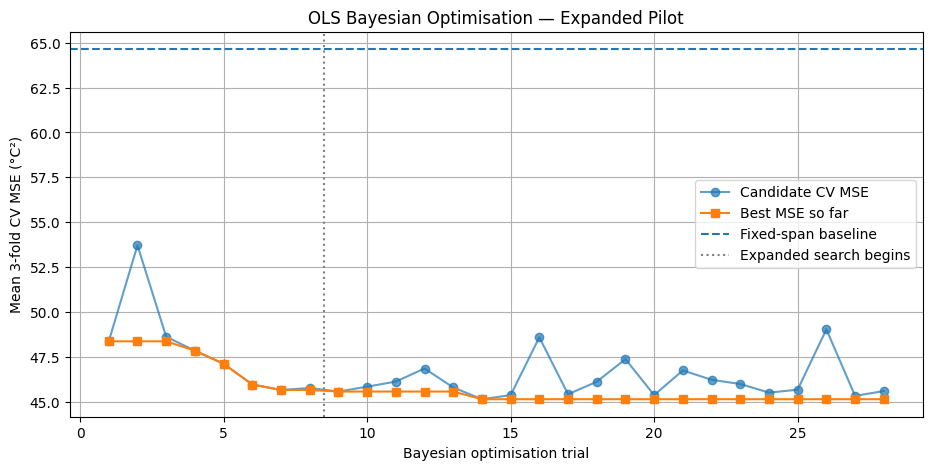

Original pilot best MSE: 45.6467
Expanded search best MSE: 45.1303
Total evaluations: 28


In [26]:

# STEP 6.3B.3 — Compare original and expanded search

import matplotlib.pyplot as plt

history = all_trials.copy()

history["best_so_far"] = (
    history["mean_cv_mse"].cummin()
)

plt.figure(figsize=(11, 5))

plt.plot(
    history["trial"],
    history["mean_cv_mse"],
    "o-",
    label="Candidate CV MSE",
    alpha=0.7
)

plt.plot(
    history["trial"],
    history["best_so_far"],
    "s-",
    label="Best MSE so far"
)

# Original manually selected span configuration
plt.axhline(
    64.6399,
    linestyle="--",
    label="Fixed-span baseline"
)

# Mark where the expanded search begins
plt.axvline(
    8.5,
    linestyle=":",
    color="grey",
    label="Expanded search begins"
)

plt.xlabel("Bayesian optimisation trial")
plt.ylabel("Mean 3-fold CV MSE (°C²)")
plt.title("OLS Bayesian Optimisation — Expanded Pilot")
plt.legend()
plt.grid(True)
plt.show()

print("Original pilot best MSE:",
      round(pilot_df["mean_cv_mse"].min(), 4))

print("Expanded search best MSE:",
      round(history["mean_cv_mse"].min(), 4))

print("Total evaluations:", len(history))


### 4.8.3 Results of the Expanded OLS Optimisation

The lowest MSE in the expanded search occurred at **Trial 14**.

| Parameter | Initial eight-trial best | Expanded 28-trial best |
|---|---:|---:|
| Span 1 | 30 | 89 |
| Span 2 | 150 | 265 |
| Span 3 | 652 | 622 |
| Span 4 | 3000 | 3829 |
| Mean three-fold CV MSE (°C²) | 45.6467 | **45.1303** |

The expanded optimum produced fold-specific MSEs of approximately **64.9351, 36.5415 and 33.9143 °C²**. It reduced MSE by another **1.13%** relative to the eight-trial optimum and by **30.18%** relative to the original manually selected spans. The optimisation-history plot showed substantial initial improvement followed by smaller gains in the expanded stage. These are observed improvements within a limited, reduced-data search; they do not demonstrate a global optimum.

### 4.8.4 Interpretation and Limitations of the OLS Pilot

The OLS experiments showed that the choice of EWMA/EWMS spans materially affects the ability of a regression estimator to reproduce permanent-magnet temperature. Expanding search intervals was justified because an optimum at a search boundary may indicate that the candidate space is too restrictive. However, the pilot evaluated a selected subset of observations rather than all original measurements. Its objective values should not be directly compared with full-data validation scores as if the evaluation populations were identical.

The earlier preliminary OLS diagnostic also identified a severe prediction error near the beginning of profile 65. The span-search results alone do not establish that the anomaly was resolved: that would require a matched, profile-specific comparison using the optimised estimator. The 14 final test profiles remained excluded from optimisation throughout this stage.


### 4.8.5 Conclusion

Steps 6.3A and 6.3B successfully implemented, verified and expanded the Bayesian optimisation framework for OLS-based permanent-magnet temperature estimation.

The initial eight-trial search reduced average cross-validation MSE from 64.6399 to 45.6467 °C². Extending the search to 28 total evaluations further reduced the MSE to 45.1303 °C².

The completed experiments establish a functioning Bayesian optimisation procedure and provide preliminary evidence that optimised temporal-feature spans can improve predictive performance.

The next stage will extend this approach to the remaining regression algorithms before conducting the full-data benchmark.

### 4.8.3 Bayesian Optimisation of Alternative Regression Models

In [27]:

# STEP 6.3C.1 — Search spaces for five regression models

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from skopt import Optimizer
from skopt.space import Integer, Real, Categorical

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.exceptions import ConvergenceWarning


# Same expanded span search space as our OLS pilot
SPAN_SPACE = [
    Integer(5, 100, name="s1"),
    Integer(1, 400, name="gap_2"),
    Integer(1, 1500, name="gap_3"),
    Integer(1, 6000, name="gap_4")
]


# Model-specific hyperparameter spaces
MODEL_SPACES = {

    "SVR": [
        Real(1e-3, 10, prior="log-uniform", name="C"),
        Real(1e-2, 0.3, prior="log-uniform", name="epsilon")
    ],

    "k-NN": [
        Integer(1, 512, name="n_neighbors"),
        Categorical(
            ["uniform", "distance"],
            name="weights"
        )
    ],

    "Random Forest": [
        Integer(20, 100, name="n_estimators"),
        Integer(5, 30, name="max_depth"),
        Integer(2, 20, name="min_samples_split"),
        Integer(1, 10, name="min_samples_leaf"),
        Categorical(["yes", "no"], name="bootstrap")
    ],

    "Extra Trees": [
        Integer(20, 100, name="n_estimators"),
        Integer(5, 30, name="max_depth"),
        Integer(2, 20, name="min_samples_split"),
        Integer(1, 10, name="min_samples_leaf"),
        Categorical(["yes", "no"], name="bootstrap")
    ],

    "MLP": [
        Integer(1, 3, name="n_layers"),
        Integer(4, 32, name="n_units"),
        Real(1e-7, 1e-2, prior="log-uniform", name="alpha"),
        Real(
            1e-4, 1e-2,
            prior="log-uniform",
            name="learning_rate_init"
        )
    ]
}


def decode_spans(parameters):
    """Convert first span and positive gaps to four spans."""
    a, d2, d3, d4 = map(int, parameters)

    return [
        a,
        a + d2,
        a + d2 + d3,
        a + d2 + d3 + d4
    ]


# Confirm that our earlier functions and CV data exist
assert callable(build_candidate_features)
assert len(profile_cv) == 55
assert len(train_df) == 1055198

assert set(profile_cv["profile_id"]) == set(
    train_df["profile_id"]
)

assert set(profile_cv["cv_fold"]) == {1, 2, 3}

print("PASS: Five model search spaces defined")
print("Models:", list(MODEL_SPACES))


PASS: Five model search spaces defined
Models: ['SVR', 'k-NN', 'Random Forest', 'Extra Trees', 'MLP']


In [28]:

# STEP 6.3C.2 — Regression models and CV objective

def make_regressor(model_name, hp):
    """Construct a regression model from its hyperparameters."""

    if model_name == "SVR":
        return SVR(
            kernel="rbf",
            C=float(hp["C"]),
            epsilon=float(hp["epsilon"]),
            gamma="scale"
        )

    if model_name == "k-NN":
        return KNeighborsRegressor(
            n_neighbors=int(hp["n_neighbors"]),
            weights=hp["weights"],
            n_jobs=2
        )

    if model_name in ["Random Forest", "Extra Trees"]:

        estimator_class = (
            RandomForestRegressor
            if model_name == "Random Forest"
            else ExtraTreesRegressor
        )

        return estimator_class(
            n_estimators=int(hp["n_estimators"]),
            max_depth=int(hp["max_depth"]),
            min_samples_split=int(hp["min_samples_split"]),
            min_samples_leaf=int(hp["min_samples_leaf"]),
            bootstrap=(hp["bootstrap"] == "yes"),
            max_features="sqrt",
            random_state=42,
            n_jobs=2
        )

    if model_name == "MLP":

        n_layers = int(hp["n_layers"])
        n_units = int(hp["n_units"])

        return MLPRegressor(
            hidden_layer_sizes=(n_units,) * n_layers,
            activation="relu",
            solver="adam",
            alpha=float(hp["alpha"]),
            learning_rate_init=float(
                hp["learning_rate_init"]
            ),
            batch_size=64,
            max_iter=200,
            random_state=42,
            early_stopping=False
        )

    raise ValueError(f"Unknown model: {model_name}")


def evaluate_model_cv(model_name, parameters):
    """
    Evaluate model hyperparameters on the fixed
    stratified grouped 3-fold cross-validation split.
    """
    spans = decode_spans(parameters[:4])

    # Translate candidate values into named hyperparameters
    hp = {
        dimension.name: value
        for dimension, value in zip(
            MODEL_SPACES[model_name],
            parameters[4:]
        )
    }

    # Recalculate EWMA/EWMS using complete profile histories,
    # then select the same 80 observations per profile.
    X, y, profile_ids = build_candidate_features(spans)

    fold_lookup = profile_cv.set_index(
        "profile_id"
    )["cv_fold"]

    fold_ids = (
        pd.Series(profile_ids)
        .map(fold_lookup)
        .to_numpy()
    )

    assert not pd.isna(fold_ids).any()

    fold_scores = []
    convergence_warnings = 0

    for fold in [1, 2, 3]:

        training_mask = fold_ids != fold
        validation_mask = fold_ids == fold

        assert set(
            profile_ids[training_mask]
        ).isdisjoint(
            set(profile_ids[validation_mask])
        )

        estimator = make_regressor(model_name, hp)

        # Feature scaling on training fold only
        feature_pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", estimator)
        ])

        # Target scaling also fitted on training fold only
        pipeline = TransformedTargetRegressor(
            regressor=feature_pipeline,
            transformer=StandardScaler()
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)

            pipeline.fit(
                X[training_mask],
                y[training_mask]
            )

        convergence_warnings += sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        # Predictions are returned in the original °C units
        predictions = pipeline.predict(
            X[validation_mask]
        )

        if not np.isfinite(predictions).all():
            raise ValueError(
                f"{model_name} produced invalid predictions"
            )

        mse = mean_squared_error(
            y[validation_mask],
            predictions
        )

        fold_scores.append(float(mse))

    return {
        "spans": spans,
        "hyperparameters": hp,
        "fold_scores": fold_scores,
        "mean_cv_mse": float(np.mean(fold_scores)),
        "convergence_warnings": convergence_warnings
    }


print("PASS: Five-model CV objective defined")


PASS: Five-model CV objective defined


In [29]:

# ============================================================
# STEP 6.3C.3 — Automated Bayesian Optimisation
# All Five Regression Models (No Checkpointing)
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from skopt import Optimizer

# ============================================================
# 1. Configuration
# ============================================================

OUTPUT_DIR = str(BASE_DIR / "bayesian_model_pilots")
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_TRIALS = 8

MODELS = [
    "SVR",
    "k-NN",
    "Random Forest",
    "Extra Trees",
    "MLP"
]

# Convert NumPy scalar values to standard Python types
def make_json_safe(values):
    return [
        v.item() if isinstance(v, np.generic) else v
        for v in values
    ]


# ============================================================
# 2. Bayesian Optimisation Function
# ============================================================

def run_model_pilot(model_name, n_trials=8):
    """
    Run Bayesian optimisation from scratch for one model.

    No checkpoint restoration or intermediate saving.
    Results are saved only after all trials finish.
    """

    search_space = SPAN_SPACE + MODEL_SPACES[model_name]

    optimizer = Optimizer(
        dimensions=search_space,
        base_estimator="GP",
        acq_func="EI",
        acq_optimizer="sampling",
        n_initial_points=5,
        random_state=42
    )

    records = []

    print(f"\nStarting optimisation: {model_name}")

    for trial_number in range(1, n_trials + 1):

        # Bayesian optimisation proposes hyperparameters
        parameters = make_json_safe(
            optimizer.ask()
        )

        start = time.perf_counter()

        # Evaluate the configuration using grouped 3-fold CV
        evaluation = evaluate_model_cv(
            model_name,
            parameters
        )

        duration = time.perf_counter() - start

        # Update Bayesian surrogate model
        optimizer.tell(
            parameters,
            evaluation["mean_cv_mse"]
        )

        record = {
            "trial": trial_number,
            "model": model_name,
            "parameters_json": json.dumps(parameters),
            "hyperparameters_json": json.dumps(
                evaluation["hyperparameters"],
                default=lambda x: x.item()
            ),
            "s1": evaluation["spans"][0],
            "s2": evaluation["spans"][1],
            "s3": evaluation["spans"][2],
            "s4": evaluation["spans"][3],
            "fold1_mse": evaluation["fold_scores"][0],
            "fold2_mse": evaluation["fold_scores"][1],
            "fold3_mse": evaluation["fold_scores"][2],
            "mean_cv_mse": evaluation["mean_cv_mse"],
            "convergence_warnings": evaluation[
                "convergence_warnings"
            ],
            "runtime_s": duration
        }

        records.append(record)

        print(
            f"Trial {trial_number}/{n_trials} | "
            f"CV MSE = {record['mean_cv_mse']:.4f} | "
            f"Runtime = {duration:.1f}s | "
            f"Warnings = {record['convergence_warnings']}",
            flush=True
        )

    # ========================================================
    # 3. Save Results After Model Completion
    # ========================================================

    results = pd.DataFrame(records)

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
    )

    save_path = os.path.join(
        OUTPUT_DIR,
        f"{filename}_trials.csv"
    )

    results.to_csv(save_path, index=False)

    best = results.loc[
        results["mean_cv_mse"].idxmin()
    ]

    print(f"\nPASS: {model_name} completed")
    print("Best CV MSE:", round(best["mean_cv_mse"], 4))
    print("Best spans:", [
        int(best[f"s{i}"]) for i in range(1, 5)
    ])
    print("Results saved:", save_path)

    return results


# ============================================================
# 4. Automatically Optimise All Five Models
# ============================================================

all_results = {}
summary = []

overall_start = time.perf_counter()

for i, model_name in enumerate(MODELS, start=1):

    print("\n" + "=" * 60)
    print(f"MODEL {i}/{len(MODELS)}: {model_name}")
    print("=" * 60)

    results = run_model_pilot(
        model_name,
        n_trials=N_TRIALS
    )

    all_results[model_name] = results

    best = results.loc[
        results["mean_cv_mse"].idxmin()
    ]

    summary.append({
        "Model": model_name,
        "Trials": len(results),
        "Best CV MSE": best["mean_cv_mse"],
        "Span 1": int(best["s1"]),
        "Span 2": int(best["s2"]),
        "Span 3": int(best["s3"]),
        "Span 4": int(best["s4"]),
        "Total Runtime (s)": results["runtime_s"].sum(),
        "Convergence Warnings": (
            results["convergence_warnings"].sum()
        )
    })


# ============================================================
# 5. Final Comparison
# ============================================================

pilot_summary = pd.DataFrame(summary)

pilot_summary = pilot_summary.sort_values(
    "Best CV MSE"
).reset_index(drop=True)

display(pilot_summary.round(4))

# Save consolidated summary
pilot_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "five_model_pilot_summary.csv"
    ),
    index=False
)

total_duration = time.perf_counter() - overall_start

print("\n" + "=" * 60)
print("PASS: ALL FIVE BAYESIAN OPTIMISATIONS COMPLETED")
print("=" * 60)

print("Total Bayesian evaluations:", len(MODELS) * N_TRIALS)
print("Total model fits:", len(MODELS) * N_TRIALS * 3)
print("Total runtime (min):", round(total_duration / 60, 2))
print("Results directory:", OUTPUT_DIR)



MODEL 1/5: SVR

Starting optimisation: SVR
Trial 1/8 | CV MSE = 52.7923 | Runtime = 9.8s | Warnings = 0
Trial 2/8 | CV MSE = 236.1684 | Runtime = 10.4s | Warnings = 0
Trial 3/8 | CV MSE = 35.3076 | Runtime = 9.9s | Warnings = 0
Trial 4/8 | CV MSE = 44.6613 | Runtime = 12.4s | Warnings = 0
Trial 5/8 | CV MSE = 54.0400 | Runtime = 8.0s | Warnings = 0
Trial 6/8 | CV MSE = 34.2210 | Runtime = 7.5s | Warnings = 0
Trial 7/8 | CV MSE = 46.2697 | Runtime = 10.2s | Warnings = 0
Trial 8/8 | CV MSE = 41.2014 | Runtime = 7.8s | Warnings = 0

PASS: SVR completed
Best CV MSE: 34.221
Best spans: [47, 301, 1799, 6668]
Results saved: /content/bayesian_model_pilots/svr_trials.csv

MODEL 2/5: k-NN

Starting optimisation: k-NN
Trial 1/8 | CV MSE = 103.5863 | Runtime = 6.8s | Warnings = 0
Trial 2/8 | CV MSE = 77.1663 | Runtime = 6.7s | Warnings = 0
Trial 3/8 | CV MSE = 113.8197 | Runtime = 6.9s | Warnings = 0
Trial 4/8 | CV MSE = 158.4636 | Runtime = 7.0s | Warnings = 0
Trial 5/8 | CV MSE = 100.9044 | Run

,Model,Trials,Best CV MSE,Span 1,Span 2,Span 3,Span 4,Total Runtime (s),Convergence Warnings
0,SVR,8,34.2210,47,301,1799,6668,76.1038,0
1,MLP,8,36.2880,19,280,366,4698,108.5789,7
2,Random Forest,8,53.9992,7,100,462,4562,74.8920,0
3,Extra Trees,8,64.1702,67,91,1174,6805,68.4973,0
4,k-NN,8,68.9349,67,467,1120,6183,53.8437,0



PASS: ALL FIVE BAYESIAN OPTIMISATIONS COMPLETED
Total Bayesian evaluations: 40
Total model fits: 120
Total runtime (min): 6.46
Results directory: /content/bayesian_model_pilots


In [30]:

# STEP 6.3C.4 — Summarise model-specific Bayesian pilots

summary = []

for model_name in MODEL_SPACES:

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
    )

    filepath = os.path.join(
        OUTPUT_DIR,
        f"{filename}_trials.csv"
    )

    if not os.path.exists(filepath):
        print(f"Not completed: {model_name}")
        continue

    trials = pd.read_csv(filepath)

    best = trials.loc[
        trials["mean_cv_mse"].idxmin()
    ]

    summary.append({
        "Model": model_name,
        "Trials": len(trials),
        "Best CV MSE": best["mean_cv_mse"],
        "Span 1": int(best["s1"]),
        "Span 2": int(best["s2"]),
        "Span 3": int(best["s3"]),
        "Span 4": int(best["s4"]),
        "Total Runtime (s)": trials["runtime_s"].sum()
    })

pilot_summary = pd.DataFrame(summary)

if not pilot_summary.empty:
    pilot_summary = pilot_summary.sort_values(
        "Best CV MSE"
    )

    display(pilot_summary.round(4))

    pilot_summary.to_csv(
        os.path.join(
            OUTPUT_DIR, "five_model_pilot_summary.csv"
        ),
        index=False
    )


,Model,Trials,Best CV MSE,Span 1,Span 2,Span 3,Span 4,Total Runtime (s)
0,SVR,8,34.2210,47,301,1799,6668,76.1038
4,MLP,8,36.2880,19,280,366,4698,108.5789
2,Random Forest,8,53.9992,7,100,462,4562,74.8920
3,Extra Trees,8,64.1702,67,91,1174,6805,68.4973
1,k-NN,8,68.9349,67,467,1120,6183,53.8437


### 4.8.6 Bayesian Optimisation of Alternative Regression Models (Step 6.3C)

Following the OLS pilot, the same general Bayesian optimisation and grouped-CV approach was extended to **Support Vector Regression (SVR), k-Nearest Neighbours (k-NN), Random Forest, Extra Trees and Multilayer Perceptron (MLP)**. For every model, the optimiser proposed the same four ordered temporal spans together with model-specific hyperparameters. These included $C$ and $\epsilon$ for SVR; neighbour count and weighting for k-NN; ensemble size, depth, minimum split/leaf sizes and bootstrapping for tree ensembles; and number of hidden layers, units, regularisation strength and learning rate for MLP. The implementation used Scikit-learn estimators and standardised model pipelines, not a direct reproduction of every training detail in the paper's Keras experiments.

Each candidate was evaluated on the 4,400-observation development sample using the same three fixed recording-profile folds. Gaussian-process Bayesian optimisation with expected improvement was run for **eight configurations per model**, giving **40 configurations and 120 fold-level fits** across the five alternatives. The revised Run-All notebook executes the models consecutively without requiring manual model selection and saves the completed per-model trial CSVs and combined summary.

| Model | Best pilot CV MSE (°C²) | Selected spans | Convergence warnings |
|---|---:|---|---:|
| SVR | **34.2210** | (47, 301, 1799, 6668) | 0 |
| MLP | 36.2880 | (19, 280, 366, 4698) | 7 |
| Random Forest | 53.9992 | (7, 100, 462, 4562) | 0 |
| Extra Trees | 64.1702 | (67, 91, 1174, 6805) | 0 |
| k-NN | 68.9349 | (67, 467, 1120, 6183) | 0 |

SVR achieved the lowest MSE in this small-sample pilot, with MLP second. The seven MLP warnings reflected fitted networks that did not meet the solver's convergence criterion within the selected stopping settings. These warnings were recorded rather than hidden or interpreted as automatic evidence that every corresponding prediction was invalid. Eight evaluations per model were used primarily to verify the complete optimisation pipeline, not to support a definitive ranking of the six algorithms.

In [31]:

# STEP 6.3C.5 — Verify completed Bayesian pilot results

import numpy as np
import pandas as pd
import os

for model_name in MODEL_SPACES:

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
    )

    path = os.path.join(
        OUTPUT_DIR,
        f"{filename}_trials.csv"
    )

    trials = pd.read_csv(path)

    # Check trial count and numerical validity
    assert len(trials) == 8

    metrics = trials[
        ["fold1_mse", "fold2_mse",
         "fold3_mse", "mean_cv_mse"]
    ]

    assert np.isfinite(metrics.to_numpy()).all()

    # Verify the mean was calculated correctly
    calculated_mean = trials[
        ["fold1_mse", "fold2_mse", "fold3_mse"]
    ].mean(axis=1)

    np.testing.assert_allclose(
        calculated_mean,
        trials["mean_cv_mse"]
    )

    print(f"\nPASS: {model_name}")
    print("Completed trials:", len(trials))
    print("Best CV MSE:", trials["mean_cv_mse"].min())
    print(
        "Convergence warnings:",
        trials["convergence_warnings"].sum()
    )

print("\nPASS: All five Bayesian pilot results verified")



PASS: SVR
Completed trials: 8
Best CV MSE: 34.221017167594226
Convergence warnings: 0

PASS: k-NN
Completed trials: 8
Best CV MSE: 68.93492964744316
Convergence warnings: 0

PASS: Random Forest
Completed trials: 8
Best CV MSE: 53.999209194049165
Convergence warnings: 0

PASS: Extra Trees
Completed trials: 8
Best CV MSE: 64.17024383565213
Convergence warnings: 0

PASS: MLP
Completed trials: 8
Best CV MSE: 36.2879683869574
Convergence warnings: 7

PASS: All five Bayesian pilot results verified


### 4.8.7 Verification of the Five-Model Pilot
The pilot CSVs were subsequently checked to verify that each model had exactly eight recorded trials; every fold-specific and aggregate CV MSE was finite; and the recorded mean equalled the arithmetic average of the three fold errors. All five models passed these checks. The verification confirmed integrity of the recorded objective values and identified the MLP convergence warnings as the main training diagnostic requiring attention during scaling. This concluded the reduced-data Bayesian pilot stage.

## 4.9 Computational Scalability Assessment

Before attempting complete-development-data optimisation for all algorithms, computational feasibility was investigated. The development partition contained **1,055,198 observations across 55 recording profiles**, each yielding 108 original and temporal predictors. The remaining **275,618 observations from 14 profiles** were reserved for later final testing. SVR was used to establish an initial relationship between training-set size, prediction error, memory and runtime, because its kernel-based fitting cost was expected to increase substantially with sample count.

In the first SVR comparison (Step 6.3D.1), training increased from 2,880 to 5,760 rows, while the validation sample also increased from 1,520 to 3,040 rows. Training time rose from approximately 0.2256 to 0.6086 seconds; the MSE changed from 37.6411 to 34.9600 °C². Because both training and validation observations changed, the apparent improvement could not be attributed only to training-set size.

A revised experiment (Steps 6.3D.2–6.3D.3) therefore held the Fold 1 validation sample fixed at **3,040 rows** and increased training samples per profile to 80, 160, 320 and 640. The resulting MSE values were approximately **38.8348, 34.9600, 31.1479 and 32.4798 °C²**, respectively. Although performance was best at 320 in this particular comparison, independently generated samples were not strictly nested and only one validation fold was examined. A more controlled analysis was consequently required.

In [32]:

# STEP 6.3D.1 — Preliminary SVR scalability experiment

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.exceptions import ConvergenceWarning

MODEL_NAME = "SVR"
SAMPLE_SIZES = [80, 160]

# Load the best previously optimised configuration
trial_path = os.path.join(
    OUTPUT_DIR, "svr_trials.csv"
)

trials = pd.read_csv(trial_path)

best = trials.loc[
    trials["mean_cv_mse"].idxmin()
]

spans = [
    int(best[f"s{i}"])
    for i in range(1, 5)
]

hp = json.loads(best["hyperparameters_json"])

print("Model:", MODEL_NAME)
print("Fixed optimised spans:", spans)
print("Fixed model hyperparameters:", hp)


# Generate temporal features using full profile histories
# and select different numbers of observations afterward.

sample_blocks = {n: [] for n in SAMPLE_SIZES}

for pid, profile in train_df.groupby(
    "profile_id", sort=False
):

    X_original = make_paper_inputs(profile)

    X_full = make_temporal_features(
        X_original,
        profile["profile_id"],
        spans
    )

    for n in SAMPLE_SIZES:

        positions = np.linspace(
            0, len(profile) - 1, n, dtype=int
        )

        sample = X_full.iloc[positions].copy()

        sample["pm_target"] = (
            profile["pm"].iloc[positions].to_numpy()
        )

        sample["profile_id"] = pid

        sample_blocks[n].append(sample)


# Use the original Fold 1 validation profiles
val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

scaling_results = []

for n in SAMPLE_SIZES:

    sample_df = pd.concat(
        sample_blocks[n],
        ignore_index=True
    )

    validation_mask = sample_df[
        "profile_id"
    ].isin(val_ids)

    training = sample_df.loc[~validation_mask]
    validation = sample_df.loc[validation_mask]

    feature_columns = [
        c for c in sample_df.columns
        if c not in ["pm_target", "profile_id"]
    ]

    X_train = training[feature_columns]
    y_train = training["pm_target"]

    X_val = validation[feature_columns]
    y_val = validation["pm_target"]

    assert len(feature_columns) == 108
    assert len(sample_df) == 55 * n

    assert set(training["profile_id"]).isdisjoint(
        set(validation["profile_id"])
    )

    # Reconstruct the selected SVR configuration
    estimator = make_regressor(MODEL_NAME, hp)

    pipeline = TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("model", estimator)
        ]),
        transformer=StandardScaler()
    )

    # Training time
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    # Inference time
    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    mse = mean_squared_error(y_val, predictions)

    # Memory occupied by the numeric input matrices
    matrix_mb = (
        X_train.to_numpy().nbytes
        + X_val.to_numpy().nbytes
    ) / 1e6

    scaling_results.append({
        "Samples/Profile": n,
        "Train Rows": len(X_train),
        "Validation Rows": len(X_val),
        "Training Time (s)": train_time,
        "Inference Time (s)": inference_time,
        "Input Matrix (MB)": matrix_mb,
        "Validation MSE": mse
    })

    print(f"PASS: {n} observations/profile evaluated")

scaling_df = pd.DataFrame(scaling_results)

display(scaling_df.round(4))

scaling_df.to_csv(
    "svr_scalability_pilot.csv",
    index=False
)


Model: SVR
Fixed optimised spans: [47, 301, 1799, 6668]
Fixed model hyperparameters: {'C': 1.573090181238779, 'epsilon': 0.18308574912799475}
PASS: 80 observations/profile evaluated
PASS: 160 observations/profile evaluated


,Samples/Profile,Train Rows,Validation Rows,Training Time (s),Inference Time (s),Input Matrix (MB),Validation MSE
0,80,2880,1520,0.2256,0.1254,3.8016,37.6411
1,160,5760,3040,0.6086,0.3689,7.6032,34.9600


In [33]:

# STEP 6.3D.2 — Controlled SVR scalability comparison
# Keep validation data fixed while increasing training size

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import time
import numpy as np
import pandas as pd

# Same validation profiles for both experiments
val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

# Fixed validation dataset: 160 samples per profile
full_160 = pd.concat(
    sample_blocks[160], ignore_index=True
)

fixed_val = full_160[
    full_160["profile_id"].isin(val_ids)
].copy()

feature_cols = [
    c for c in fixed_val.columns
    if c not in ["pm_target", "profile_id"]
]

X_val = fixed_val[feature_cols]
y_val = fixed_val["pm_target"]

assert len(fixed_val) == 19 * 160

controlled_results = []

for n in [80, 160]:

    sample_df = pd.concat(
        sample_blocks[n], ignore_index=True
    )

    # Training data changes, validation data does not
    training = sample_df[
        ~sample_df["profile_id"].isin(val_ids)
    ]

    X_train = training[feature_cols]
    y_train = training["pm_target"]

    assert set(training["profile_id"]).isdisjoint(
        set(fixed_val["profile_id"])
    )

    pipeline = TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("model", make_regressor("SVR", hp))
        ]),
        transformer=StandardScaler()
    )

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    mse = mean_squared_error(y_val, predictions)

    controlled_results.append({
        "Training Samples/Profile": n,
        "Training Rows": len(X_train),
        "Fixed Validation Rows": len(X_val),
        "Training Time (s)": train_time,
        "Inference Time (s)": inference_time,
        "Validation MSE": mse
    })

controlled_df = pd.DataFrame(controlled_results)

display(controlled_df.round(4))

controlled_df.to_csv(
    "svr_scalability_controlled.csv",
    index=False
)

print("PASS: Fixed-validation scalability comparison")


,Training Samples/Profile,Training Rows,Fixed Validation Rows,Training Time (s),Inference Time (s),Validation MSE
0,80,2880,3040,0.2277,0.2578,38.8348
1,160,5760,3040,0.5972,0.3683,34.9600


PASS: Fixed-validation scalability comparison


In [34]:

# STEP 6.3D.3 — Expand SVR scalability assessment

# Generate larger sampled datasets from the full
# original 2 Hz temporal histories.

for n in [320, 640]:
    sample_blocks[n] = []

for pid, profile in train_df.groupby(
    "profile_id", sort=False
):

    X_original = make_paper_inputs(profile)

    X_full = make_temporal_features(
        X_original,
        profile["profile_id"],
        spans
    )

    for n in [320, 640]:

        positions = np.linspace(
            0, len(profile) - 1,
            n, dtype=int
        )

        sample = X_full.iloc[positions].copy()

        sample["pm_target"] = (
            profile["pm"].iloc[positions].to_numpy()
        )

        sample["profile_id"] = pid

        sample_blocks[n].append(sample)

print("PASS: Larger training samples generated")


PASS: Larger training samples generated


In [35]:

# STEP 6.3D.2 — Second part of doing the Controlled SVR scalability comparison
# but changing from for n in [80, 160]: to for n in [80, 160, 320, 640]:
# Keep validation data fixed while increasing training size

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import time
import numpy as np
import pandas as pd

# Same validation profiles for both experiments
val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

# Fixed validation dataset: 160 samples per profile
full_160 = pd.concat(
    sample_blocks[160], ignore_index=True
)

fixed_val = full_160[
    full_160["profile_id"].isin(val_ids)
].copy()

feature_cols = [
    c for c in fixed_val.columns
    if c not in ["pm_target", "profile_id"]
]

X_val = fixed_val[feature_cols]
y_val = fixed_val["pm_target"]

assert len(fixed_val) == 19 * 160

controlled_results = []

for n in [80, 160, 320, 640]:

    sample_df = pd.concat(
        sample_blocks[n], ignore_index=True
    )

    # Training data changes, validation data does not
    training = sample_df[
        ~sample_df["profile_id"].isin(val_ids)
    ]

    X_train = training[feature_cols]
    y_train = training["pm_target"]

    assert set(training["profile_id"]).isdisjoint(
        set(fixed_val["profile_id"])
    )

    pipeline = TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("model", make_regressor("SVR", hp))
        ]),
        transformer=StandardScaler()
    )

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    mse = mean_squared_error(y_val, predictions)

    controlled_results.append({
        "Training Samples/Profile": n,
        "Training Rows": len(X_train),
        "Fixed Validation Rows": len(X_val),
        "Training Time (s)": train_time,
        "Inference Time (s)": inference_time,
        "Validation MSE": mse
    })

controlled_df = pd.DataFrame(controlled_results)

display(controlled_df.round(4))

controlled_df.to_csv(
    "svr_scalability_controlled.csv",
    index=False
)

print("PASS: Fixed-validation scalability comparison")


,Training Samples/Profile,Training Rows,Fixed Validation Rows,Training Time (s),Inference Time (s),Validation MSE
0,80,2880,3040,0.2283,0.2526,38.8348
1,160,5760,3040,0.6093,0.3418,34.9600
2,320,11520,3040,1.6756,0.5137,31.1479
3,640,23040,3040,4.3657,0.6395,32.4798


PASS: Fixed-validation scalability comparison


### 4.9.1 Construction and Verification of Nested Training Samples (Step 6.3D.4A)

A hierarchical, interval-bisection sampling method was implemented so that every smaller training set was contained in the larger ones:

$$
A_{80} \subset A_{160} \subset A_{320} \subset A_{640}
$$

For each profile, the first and last observations were selected initially, followed by repeated subdivision of the largest remaining sampling intervals. The selections were then put into chronological order. This ensured that increasing the number of training observations added points rather than replacing the previously selected points. The same four sample sizes corresponded to **4,400; 8,800; 17,600; and 35,200** selected development observations before fold partitioning.

The best SVR pilot configuration, spans **(47, 301, 1799, 6668)** with $C\approx1.5731$ and $\epsilon\approx0.1831$, was kept fixed to isolate the influence of training size. EWMA/EWMS features were still computed from each complete 2 Hz profile before nested sampling. Assertions verified the numbers of profiles, the 108-feature matrix, finite values, sampling counts and nested membership. Feature construction for this experiment took approximately **6.48 seconds** in the recorded run.

In [36]:

# STEP 6.3D.4A — Construct nested sample positions

import os
import json
import time
import heapq
import numpy as np
import pandas as pd

SAMPLE_SIZES = [80, 160, 320, 640]
MAX_SAMPLES = max(SAMPLE_SIZES)

# Restore the best SVR pilot configuration
svr_trials = pd.read_csv(
    os.path.join(OUTPUT_DIR, "svr_trials.csv")
)

best_svr = svr_trials.loc[
    svr_trials["mean_cv_mse"].idxmin()
]

svr_spans = [
    int(best_svr[f"s{i}"])
    for i in range(1, 5)
]

svr_hp = json.loads(
    best_svr["hyperparameters_json"]
)


def nested_sample_order(profile_length, max_samples):
    """
    Return observation positions in nested selection order.

    Begin with the first and last observations.
    Repeatedly bisect the largest remaining interval.

    The first 80 selected positions are contained in
    the first 160, 320, and 640 selected positions.
    """
    if profile_length < max_samples:
        raise ValueError("Profile contains too few observations")

    selected = [0, profile_length - 1]

    intervals = [
        (-(profile_length - 1), 0, profile_length - 1)
    ]

    while len(selected) < max_samples:

        _, left, right = heapq.heappop(intervals)

        middle = (left + right) // 2

        if middle in (left, right):
            continue

        selected.append(middle)

        for a, b in [(left, middle), (middle, right)]:
            if b - a > 1:
                heapq.heappush(
                    intervals, (-(b - a), a, b)
                )

    return selected


print("Optimised SVR spans:", svr_spans)
print("Model hyperparameters:", svr_hp)

# Build temporal features from complete recording histories
start_features = time.perf_counter()

nested_blocks = []

for pid, profile in train_df.groupby(
    "profile_id", sort=False
):

    # Preserve original chronological order
    assert profile.index.is_monotonic_increasing

    order = nested_sample_order(
        len(profile), MAX_SAMPLES
    )

    # Selected positions, ordered chronologically
    positions = np.sort(
        np.asarray(order, dtype=int)
    )

    # Rank tells us when each position was added
    rank_lookup = {
        position: rank
        for rank, position in enumerate(order)
    }

    X_original = make_paper_inputs(profile)

    # Use the FULL 2 Hz history before sampling
    X_full = make_temporal_features(
        X_original,
        profile["profile_id"],
        svr_spans
    )

    sample = X_full.iloc[positions].copy()

    sample["pm_target"] = (
        profile["pm"].iloc[positions].to_numpy()
    )

    sample["profile_id"] = pid

    sample["nest_rank"] = [
        rank_lookup[position]
        for position in positions
    ]

    nested_blocks.append(sample)

nested_df = pd.concat(
    nested_blocks, ignore_index=True
)

feature_generation_time = (
    time.perf_counter() - start_features
)

# Verify full sample
assert len(nested_df) == 55 * MAX_SAMPLES
assert nested_df["profile_id"].nunique() == 55
assert nested_df["nest_rank"].between(
    0, MAX_SAMPLES - 1
).all()

FEATURE_COLS = [
    c for c in nested_df.columns
    if c not in [
        "pm_target", "profile_id", "nest_rank"
    ]
]

assert len(FEATURE_COLS) == 108
assert np.isfinite(
    nested_df[FEATURE_COLS + ["pm_target"]].to_numpy()
).all()

# Verify nested membership and observation counts
for n in SAMPLE_SIZES:

    subset = nested_df[
        nested_df["nest_rank"] < n
    ]

    counts = subset.groupby("profile_id").size()

    assert len(subset) == 55 * n
    assert (counts == n).all()

    print(
        f"PASS: {n} observations/profile "
        f"({len(subset):,} observations)"
    )

print("\nPASS: All training samples are nested")
print("Predictor features:", len(FEATURE_COLS))
print(
    "Feature generation time:",
    round(feature_generation_time, 2), "seconds"
)


Optimised SVR spans: [47, 301, 1799, 6668]
Model hyperparameters: {'C': 1.573090181238779, 'epsilon': 0.18308574912799475}
PASS: 80 observations/profile (4,400 observations)
PASS: 160 observations/profile (8,800 observations)
PASS: 320 observations/profile (17,600 observations)
PASS: 640 observations/profile (35,200 observations)

PASS: All training samples are nested
Predictor features: 108
Feature generation time: 6.48 seconds


### 4.9.2 Three-Fold Cross-Validation and Computational Timing (Step 6.3D.4B)

The nested SVR evaluation was extended to all three established grouped folds, retaining the same **640 validation observations per validation profile** at every training size. Consequently, Fold 1 used 12,160 validation rows, while Folds 2 and 3 each used 11,520. Training observations increased with the selected nested subset, but the validation cases remained fixed within each fold. Training and validation profile IDs were checked for non-overlap.

Each of the four sample sizes was evaluated on three folds, with **three repetitions of fitting and timing for each condition**, yielding **36 model fits**. The code recorded fold-level MSE, training time, inference time and number of SVR support vectors. Median training and inference times across repetitions were used to reduce sensitivity to short-term runtime fluctuations. Repetitions of this fixed-seed configuration served mainly to assess timing variation; they were not independent training-profile splits.

In [37]:

# STEP 6.3D.4B — Nested 3-fold SVR scalability

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import time
import pandas as pd
import numpy as np

N_REPEATS = 3

RESULT_PATH = "svr_nested_scalability_v1.csv"

# Fresh execution: no restoration of old checkpoint CSVs.
records = []

fold_lookup = profile_cv.set_index(
    "profile_id"
)["cv_fold"]

nested_df["cv_fold"] = (
    nested_df["profile_id"]
    .map(fold_lookup)
    .astype(int)
)

assert nested_df["cv_fold"].isin([1, 2, 3]).all()


for n in SAMPLE_SIZES:

    for fold in [1, 2, 3]:

        # Training data changes with n
        training = nested_df.loc[
            (nested_df["cv_fold"] != fold)
            & (nested_df["nest_rank"] < n)
        ]

        # Validation data ALWAYS uses 640
        # observations per validation profile
        validation = nested_df.loc[
            nested_df["cv_fold"] == fold
        ]

        X_train = training[FEATURE_COLS]
        y_train = training["pm_target"]

        X_val = validation[FEATURE_COLS]
        y_val = validation["pm_target"]

        train_ids = set(training["profile_id"])
        val_ids = set(validation["profile_id"])

        assert train_ids.isdisjoint(val_ids)

        assert len(X_train) == len(train_ids) * n
        assert len(X_val) == len(val_ids) * MAX_SAMPLES

        for repeat in range(1, N_REPEATS + 1):

            estimator = make_regressor(
                "SVR", svr_hp
            )

            # Fit scalers exclusively on training fold
            pipeline = TransformedTargetRegressor(
                regressor=Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", estimator)
                ]),
                transformer=StandardScaler()
            )

            # Time model training
            start = time.perf_counter()

            pipeline.fit(X_train, y_train)

            training_time = time.perf_counter() - start

            # Time prediction on fixed validation data
            start = time.perf_counter()

            predictions = pipeline.predict(X_val)

            inference_time = time.perf_counter() - start

            mse = mean_squared_error(
                y_val, predictions
            )

            fitted_svr = (
                pipeline.regressor_
                .named_steps["model"]
            )

            record = {
                "Samples_per_Profile": n,
                "Fold": fold,
                "Repeat": repeat,
                "Training_Rows": len(X_train),
                "Validation_Rows": len(X_val),
                "Training_Time_s": training_time,
                "Inference_Time_s": inference_time,
                "MSE": float(mse),
                "Support_Vectors": len(
                    fitted_svr.support_
                )
            }

            records.append(record)
            print(
                f"n={n}, fold={fold}, "
                f"repeat={repeat}: "
                f"MSE={mse:.4f}, "
                f"train={training_time:.2f}s",
                flush=True
            )

results_df = pd.DataFrame(records)
results_df.to_csv(RESULT_PATH, index=False)

# Check all 36 requested runs are present
expected_runs = (
    len(SAMPLE_SIZES) * 3 * N_REPEATS
)

assert len(results_df) == expected_runs
assert np.isfinite(
    results_df[
        ["MSE", "Training_Time_s", "Inference_Time_s"]
    ].to_numpy()
).all()

print(
    "\nPASS: All",
    expected_runs,
    "SVR training/evaluation runs completed"
)


n=80, fold=1, repeat=1: MSE=41.1305, train=0.23s
n=80, fold=1, repeat=2: MSE=41.1305, train=0.24s
n=80, fold=1, repeat=3: MSE=41.1305, train=0.23s
n=80, fold=2, repeat=1: MSE=31.8229, train=0.26s
n=80, fold=2, repeat=2: MSE=31.8229, train=0.25s
n=80, fold=2, repeat=3: MSE=31.8229, train=0.26s
n=80, fold=3, repeat=1: MSE=36.1783, train=0.24s
n=80, fold=3, repeat=2: MSE=36.1783, train=0.25s
n=80, fold=3, repeat=3: MSE=36.1783, train=0.24s
n=160, fold=1, repeat=1: MSE=38.2014, train=0.69s
n=160, fold=1, repeat=2: MSE=38.2014, train=0.61s
n=160, fold=1, repeat=3: MSE=38.2014, train=0.62s
n=160, fold=2, repeat=1: MSE=31.3518, train=0.63s
n=160, fold=2, repeat=2: MSE=31.3518, train=0.64s
n=160, fold=2, repeat=3: MSE=31.3518, train=0.70s
n=160, fold=3, repeat=1: MSE=39.7700, train=0.61s
n=160, fold=3, repeat=2: MSE=39.7700, train=0.61s
n=160, fold=3, repeat=3: MSE=39.7700, train=0.61s
n=320, fold=1, repeat=1: MSE=35.0565, train=1.79s
n=320, fold=1, repeat=2: MSE=35.0565, train=1.76s
n=320, fo

### 4.9.3 Assessment of Prediction Accuracy and Computational Scalability (Step 6.3D.4C–D)

| Samples/profile | Mean three-fold CV MSE (°C²) | Between-fold MSE SD (°C²) | Total three-fold training time (s) | Mean support vectors |
|---|---:|---:|---:|---:|
| 80 | 36.3772 | 4.6570 | 0.7386 | 667.7 |
| 160 | 36.4411 | 4.4767 | 1.8672 | 952.7 |
| 320 | **36.0818** | 5.1517 | 5.0677 | 1321.7 |
| 640 | 38.3040 | 6.5129 | 13.5167 | 1721.3 |

With the fixed pilot hyperparameters, 320 observations per profile gave the smallest mean CV MSE among the four tested sizes. The move to 640 observations did not improve accuracy, while the summed fold training time increased from approximately 5.07 to 13.52 seconds. The mean number of support vectors also grew from approximately 668 at the smallest size to 1,721 at the largest, suggesting increasing potential inference cost.

Fold-level analysis showed that MSE increased from 320 to 640 observations per profile in **all three folds**. The changes were approximately **+3.1633, +0.3136 and +3.1895 °C²** for Folds 1–3 respectively. Nevertheless, this does not prove that additional data intrinsically worsens SVR. The hyperparameters were optimised for a smaller sample and were held fixed, so they might not be appropriate for the expanded training distributions. The purpose of this experiment was to inform resource allocation, not to present a new learning-curve result as the independent research contribution.

Results for each validation fold:


,Samples_per_Profile,Fold,MSE,Training_Rows,Validation_Rows,Training_Time_s,Inference_Time_s,Support_Vectors
0,80,1,41.1305,2880,12160,0.2336,1.0824,689.0
1,80,2,31.8229,2960,11520,0.2613,1.0076,687.0
2,80,3,36.1783,2960,11520,0.2437,0.9193,627.0
3,160,1,38.2014,5760,12160,0.6239,1.4874,997.0
4,160,2,31.3518,5920,11520,0.6372,1.3857,950.0
5,160,3,39.7700,5920,11520,0.6061,1.2941,911.0
6,320,1,35.0565,11520,12160,1.7642,2.1122,1401.0
7,320,2,31.5199,11840,11520,1.7924,1.9516,1343.0
8,320,3,41.6691,11840,11520,1.5110,1.7897,1221.0
9,640,1,38.2199,23040,12160,4.6286,2.7847,1857.0



Overall scalability summary:


,Samples_per_Profile,Mean_CV_MSE,Fold_MSE_SD,Total_3Fold_Training_s,Total_3Fold_Inference_s,Mean_Support_Vectors
0,80,36.3772,4.6570,0.7386,3.0093,667.6667
1,160,36.4411,4.4767,1.8672,4.1672,952.6667
2,320,36.0818,5.1517,5.0677,5.8536,1321.6667
3,640,38.3040,6.5129,13.5167,7.5992,1721.3333


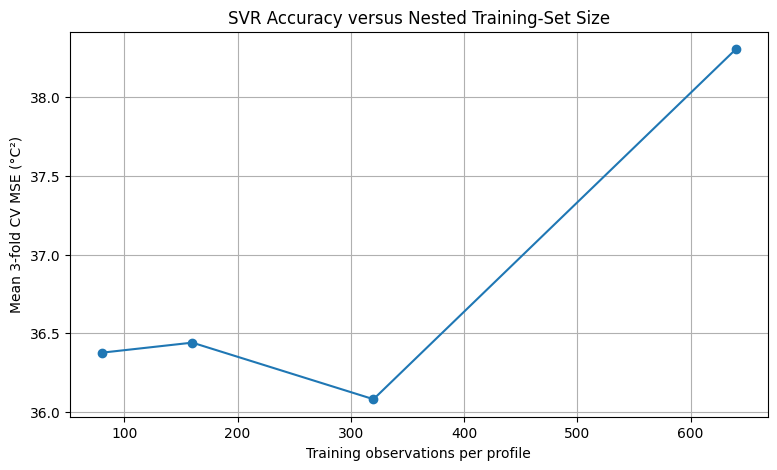

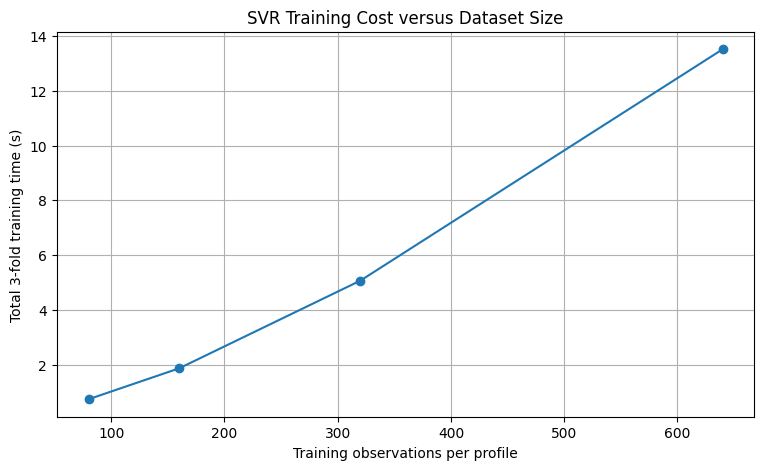

PASS: Scalability analysis completed


In [38]:

# STEP 6.3D.4C — Summarise nested scalability results

import pandas as pd
import matplotlib.pyplot as plt

# Average repeated results within each fold
fold_results = (
    results_df.groupby(
        ["Samples_per_Profile", "Fold"],
        as_index=False
    )
    .agg(
        MSE=("MSE", "mean"),
        Training_Rows=("Training_Rows", "first"),
        Validation_Rows=("Validation_Rows", "first"),
        Training_Time_s=("Training_Time_s", "median"),
        Inference_Time_s=("Inference_Time_s", "median"),
        Support_Vectors=("Support_Vectors", "median")
    )
)

print("Results for each validation fold:")
display(fold_results.round(4))


# Aggregate across all three folds
scalability_summary = (
    fold_results.groupby(
        "Samples_per_Profile",
        as_index=False
    )
    .agg(
        Mean_CV_MSE=("MSE", "mean"),
        Fold_MSE_SD=("MSE", "std"),
        Total_3Fold_Training_s=("Training_Time_s", "sum"),
        Total_3Fold_Inference_s=("Inference_Time_s", "sum"),
        Mean_Support_Vectors=("Support_Vectors", "mean")
    )
)

print("\nOverall scalability summary:")
display(scalability_summary.round(4))

scalability_summary.to_csv(
    "svr_nested_scalability_summary.csv",
    index=False
)


# Graph 1 — Accuracy versus training size
plt.figure(figsize=(9, 5))

plt.plot(
    scalability_summary["Samples_per_Profile"],
    scalability_summary["Mean_CV_MSE"],
    marker="o"
)

plt.xlabel("Training observations per profile")
plt.ylabel("Mean 3-fold CV MSE (°C²)")
plt.title("SVR Accuracy versus Nested Training-Set Size")
plt.grid(True)
plt.show()


# Graph 2 — Computational cost
plt.figure(figsize=(9, 5))

plt.plot(
    scalability_summary["Samples_per_Profile"],
    scalability_summary["Total_3Fold_Training_s"],
    marker="o"
)

plt.xlabel("Training observations per profile")
plt.ylabel("Total 3-fold training time (s)")
plt.title("SVR Training Cost versus Dataset Size")
plt.grid(True)
plt.show()

print("PASS: Scalability analysis completed")


In [39]:

# STEP 6.3D.4D — Inspect fold-level accuracy differences

fold_mse_table = fold_results.pivot(
    index="Samples_per_Profile",
    columns="Fold",
    values="MSE"
)

print("Validation MSE across the three folds:")
display(fold_mse_table.round(4))

print("\nChange in MSE from 320 to 640 samples/profile:")

mse_change = (
    fold_mse_table.loc[640]
    - fold_mse_table.loc[320]
)

display(
    pd.DataFrame({
        "MSE change (°C²)": mse_change
    }).round(4)
)


Validation MSE across the three folds:


Fold,1,2,3
Samples_per_Profile,,,
80,41.1305,31.8229,36.1783
160,38.2014,31.3518,39.7700
320,35.0565,31.5199,41.6691
640,38.2199,31.8335,44.8586



Change in MSE from 320 to 640 samples/profile:


,MSE change (°C²)
Fold,
1,3.1633
2,0.3136
3,3.1895


### 4.9.4 Full-Development-Data OLS Feasibility Assessment (Step 6.3D.5A)

The analysis next returned to OLS to determine whether a full-development-data benchmark was computationally feasible. Directly storing more than one million observations with 108 `float64` predictors would require approximately **0.91 GB for the predictor array alone**, excluding intermediate Pandas arrays and processing overhead. A profile-wise, memory-conscious QR decomposition was therefore implemented to preserve the information needed for linear least-squares fitting and residual calculation.

Each complete recording profile was processed at the original 2 Hz rate. Its 108 temporal and original predictors, an intercept column and the permanent-magnet temperature target were combined into an augmented regression matrix. QR compression was applied in blocks and then combined within the profile, retaining a small triangular factor and summary statistics instead of preserving the complete multi-profile predictor matrix. In each CV fold, the training-profile means and variances were combined to obtain training-only standardisation, and OLS coefficients were solved using a rank-aware least-squares method. Validation residual sums of squares were computed from the QR factors of the held-out development profiles.

A numerical check compared directly calculated residual sums of squares with QR-compressed residual sums of squares for a representative profile. The values agreed within numerical precision (**1080.94694** in both calculations), supporting the residual-preservation implementation.

In [40]:

# STEP 6.3D.5A — Memory-efficient full-data OLS

import time
import numpy as np
import pandas as pd

from scipy.linalg import qr, lstsq

# We retain all 55 original development profiles.
assert len(train_df) == 1055198
assert train_df["profile_id"].nunique() == 55

# Original grouped CV assignments from Step 6.1
cv_lookup = (
    profile_cv.set_index("profile_id")["cv_fold"]
    .astype(int)
    .to_dict()
)

assert set(cv_lookup.values()) == {1, 2, 3}


def compress_profile_ols(profile, spans, chunk_size=4096):
    """
    Compress one full recording profile using QR.

    Parameters
    ----------
    profile : pandas.DataFrame
        Original 2 Hz measurements from one recording profile.
    spans : list of int
        Four EWMA/EWMS smoothing spans.
    chunk_size : int
        Maximum observations processed per QR block.

    Returns
    -------
    dict
        Profile size, predictor statistics and compressed R.
    """
    # Build the 12 original and derived input variables
    X_original = make_paper_inputs(profile)

    # Build all 108 predictors from the FULL time history
    X_temporal = make_temporal_features(
        X_original,
        profile["profile_id"],
        spans
    )

    X = X_temporal.to_numpy(dtype=np.float64)
    y = profile["pm"].to_numpy(dtype=np.float64)

    n, p = X.shape

    assert p == 108
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    # Per-profile statistics for fold-specific scaling
    feature_mean = X.mean(axis=0)
    feature_var = X.var(axis=0)

    # Augmented matrix: [intercept, predictors, target]
    n_columns = p + 2
    R_profile = None

    for start in range(0, n, chunk_size):

        stop = min(start + chunk_size, n)
        size = stop - start

        block = np.empty(
            (size, n_columns),
            dtype=np.float64
        )

        block[:, 0] = 1.0
        block[:, 1:-1] = X[start:stop]
        block[:, -1] = y[start:stop]

        # Keep the compressed triangular factor.
        R_block = qr(
            block,
            mode="r",
            check_finite=False
        )[0][:n_columns, :]

        if R_profile is None:
            R_profile = R_block
        else:
            # Combine QR factors without storing old blocks
            combined = np.vstack([
                R_profile, R_block
            ])

            R_profile = qr(
                combined,
                mode="r",
                check_finite=False
            )[0][:n_columns, :]

    return {
        "n": n,
        "mean": feature_mean,
        "var": feature_var,
        "R": R_profile
    }


def evaluate_full_ols_cv(spans):
    """
    Evaluate an OLS configuration on all development rows.

    Uses profile-wise QR compression and training-fold-only
    standardisation. No test profiles are accessed.
    """
    start_total = time.perf_counter()

    profile_stats = {}

    # =================================================
    # A — Construct and compress all 55 profiles
    # =================================================

    for count, (pid, profile) in enumerate(
        train_df.groupby("profile_id", sort=False),
        start=1
    ):

        pid = int(pid)

        profile_stats[pid] = compress_profile_ols(
            profile,
            spans
        )

        if count % 10 == 0 or count == 55:
            print(
                f"Processed {count}/55 profiles",
                flush=True
            )

    feature_time = time.perf_counter() - start_total

    # =================================================
    # B — Evaluate the same three grouped CV folds
    # =================================================

    start_cv = time.perf_counter()

    fold_results = []

    for fold in [1, 2, 3]:

        training_ids = [
            pid for pid in profile_stats
            if cv_lookup[pid] != fold
        ]

        validation_ids = [
            pid for pid in profile_stats
            if cv_lookup[pid] == fold
        ]

        assert set(training_ids).isdisjoint(
            set(validation_ids)
        )

        # Calculate training-fold-only feature statistics
        n_train = sum(
            profile_stats[pid]["n"]
            for pid in training_ids
        )

        mu = sum(
            profile_stats[pid]["n"]
            * profile_stats[pid]["mean"]
            for pid in training_ids
        ) / n_train

        variance = sum(
            profile_stats[pid]["n"] * (
                profile_stats[pid]["var"]
                + (
                    profile_stats[pid]["mean"] - mu
                ) ** 2
            )
            for pid in training_ids
        ) / n_train

        scale = np.sqrt(np.maximum(variance, 0))

        # Match StandardScaler behaviour for zero variance
        scale[scale == 0] = 1.0

        # Combine compressed training matrices
        R_train = np.vstack([
            profile_stats[pid]["R"]
            for pid in training_ids
        ])

        # Apply training-fold standardisation algebraically
        R_scaled = R_train.copy()

        R_scaled[:, 1:-1] = (
            R_train[:, 1:-1]
            - R_train[:, [0]] * mu
        ) / scale

        # Fit OLS by rank-aware least squares
        coefficients, _, rank, singular_values = lstsq(
            R_scaled[:, :-1],
            R_scaled[:, -1],
            lapack_driver="gelsd"
        )

        # Convert fitted coefficients to raw feature units
        beta = coefficients[1:] / scale

        intercept = (
            coefficients[0]
            - np.dot(mu, beta)
        )

        # Residual coefficient vector in original units
        residual_vector = np.concatenate([
            [intercept],
            beta,
            [-1.0]
        ])

        # Compute validation SSE from compressed R factors
        n_validation = 0
        validation_sse = 0.0

        for pid in validation_ids:

            R = profile_stats[pid]["R"]

            residuals_compressed = (
                R @ residual_vector
            )

            validation_sse += float(
                np.dot(
                    residuals_compressed,
                    residuals_compressed
                )
            )

            n_validation += profile_stats[pid]["n"]

        mse = validation_sse / n_validation

        assert np.isfinite(mse)
        assert mse >= 0

        fold_results.append({
            "Fold": fold,
            "Training_Rows": n_train,
            "Validation_Rows": n_validation,
            "MSE": mse,
            "Numerical_Rank": rank
        })

    cv_time = time.perf_counter() - start_cv

    results = pd.DataFrame(fold_results)

    mean_cv_mse = results["MSE"].mean()

    return {
        "spans": list(map(int, spans)),
        "fold_results": results,
        "mean_cv_mse": float(mean_cv_mse),
        "feature_time_s": feature_time,
        "cv_time_s": cv_time,
        "total_time_s": time.perf_counter() - start_total
    }


print("PASS: Full-data OLS evaluation function defined")


PASS: Full-data OLS evaluation function defined


### 4.9.5 Initial Full-Data OLS Evaluation and Computational Timing (Step 6.3D.5B)

The best expanded-pilot spans, **(89, 265, 622, 3829)**, were evaluated on **all 1,055,198 development observations** using the QR-based implementation and the original grouped CV assignments.

| Fold | Training rows | Validation rows | MSE (°C²) | Numerical rank |
|---|---:|---:|---:|---:|
| 1 | 654,084 | 401,114 | 31.6606 | 109 |
| 2 | 693,111 | 362,087 | 27.3374 | 109 |
| 3 | 763,201 | 291,997 | 34.0522 | 109 |
| **Mean CV MSE** | — | — | **31.0167** | — |

The recorded run required approximately **15.77 seconds** for profile feature generation and QR compression and **0.09 seconds** for the three-fold least-squares fitting and evaluation, for **15.85 seconds overall**. These results identified feature preparation rather than solving OLS as the main measured computational bottleneck. Numerical rank 109 was obtained in every fold, consistent with 108 predictors plus an intercept, although full rank alone does not establish good conditioning.

The MSE of 31.0167 °C² is lower than the reduced-data pilot's 45.1303 °C², but the two scores use different validation observation sets and therefore cannot isolate the effect of additional training data.

In [41]:

# STEP 6.3D.5 — Verify QR compression numerically

import numpy as np

# Use a small subset of an existing development profile
pid = int(profile_cv["profile_id"].iloc[0])

demo = train_df.loc[
    train_df["profile_id"] == pid
].head(300).copy()

spans = [89, 265, 622, 3829]

X_demo = make_temporal_features(
    make_paper_inputs(demo),
    demo["profile_id"],
    spans
).to_numpy(dtype=np.float64)

y_demo = demo["pm"].to_numpy(dtype=np.float64)

compressed = compress_profile_ols(
    demo, spans, chunk_size=128
)

# A deliberately chosen example regression equation
w = np.zeros(110)
w[0] = 25.0
w[1] = 0.01
w[-1] = -1.0

# Calculate the residual sum of squares directly
direct_residuals = (
    w[0] + 0.01 * X_demo[:, 0] - y_demo
)

direct_sse = np.sum(direct_residuals**2)

# Calculate equivalent residuals from QR factor
compressed_sse = np.sum(
    (compressed["R"] @ w)**2
)

np.testing.assert_allclose(
    direct_sse,
    compressed_sse,
    rtol=1e-8
)

print("PASS: QR residual calculation verified")
print("Direct SSE:", direct_sse)
print("Compressed SSE:", compressed_sse)


PASS: QR residual calculation verified
Direct SSE: 1080.9469395699446
Compressed SSE: 1080.9469395699728


In [42]:

# STEP 6.3D.5B — First full-data OLS feasibility run

import time
import pandas as pd

# Best spans from our expanded 28-trial pilot
candidate_spans = [89, 265, 622, 3829]

print("Evaluating full-data OLS configuration")
print("Spans:", candidate_spans)
print("Development observations:", len(train_df))

full_ols_result = evaluate_full_ols_cv(
    candidate_spans
)

print("\nPASS: Full-data OLS evaluation completed")

print("\nIndividual fold results:")
display(
    full_ols_result["fold_results"].round(4)
)

print(
    "\nMean 3-fold CV MSE:",
    round(full_ols_result["mean_cv_mse"], 4),
    "°C²"
)

print(
    "Feature generation and compression:",
    round(full_ols_result["feature_time_s"], 2),
    "seconds"
)

print(
    "Cross-validation fitting and evaluation:",
    round(full_ols_result["cv_time_s"], 2),
    "seconds"
)

print(
    "Total runtime:",
    round(full_ols_result["total_time_s"], 2),
    "seconds"
)

# Save results
full_ols_result["fold_results"].to_csv(
    "ols_full_data_first_trial_folds.csv",
    index=False
)

full_trial_summary = pd.DataFrame([{
    "s1": candidate_spans[0],
    "s2": candidate_spans[1],
    "s3": candidate_spans[2],
    "s4": candidate_spans[3],
    "mean_cv_mse": full_ols_result["mean_cv_mse"],
    "feature_time_s": full_ols_result["feature_time_s"],
    "cv_time_s": full_ols_result["cv_time_s"],
    "total_time_s": full_ols_result["total_time_s"]
}])

full_trial_summary.to_csv(
    "ols_full_data_first_trial_summary.csv",
    index=False
)


Evaluating full-data OLS configuration
Spans: [89, 265, 622, 3829]
Development observations: 1055198
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles

PASS: Full-data OLS evaluation completed

Individual fold results:


,Fold,Training_Rows,Validation_Rows,MSE,Numerical_Rank
0,1,654084,401114,31.6606,109
1,2,693111,362087,27.3374,109
2,3,763201,291997,34.0522,109



Mean 3-fold CV MSE: 31.0167 °C²
Feature generation and compression: 15.77 seconds
Cross-validation fitting and evaluation: 0.09 seconds
Total runtime: 15.85 seconds


### 4.9.6 Numerical Equivalence Between QR-Based OLS and Scikit-learn (Step 6.3D.6A)

A further check examined whether QR-based regression produced the same fitted predictions as Scikit-learn's `LinearRegression`, beyond the earlier residual-identity test. The comparison used the same 4,400-observation pilot dataset and Fold 1 split for both implementations. Feature standardisation was reproduced from training-profile statistics, and validation predictions were calculated using the same observations.

The maximum difference between the two sets of predictions was approximately **$1.17\times10^{-12}$ °C**. Both methods returned a validation MSE of approximately **88.6562614 °C²**, and the QR regression had numerical rank 109. The numerical assertions passed. This verified the compressed fitting and prediction procedure on the selected verification sample before its use in repeated full-data Bayesian evaluations.

In [43]:

# STEP 6.3D.6A — Verify QR-based OLS numerically

import numpy as np
import pandas as pd

from scipy.linalg import qr, lstsq
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Use the existing 4,400-observation verification dataset.
# It is based on full profile histories before subsampling.
assert len(smoke_df) == 4400
assert smoke_df["profile_id"].nunique() == 55

feature_cols = [
    c for c in smoke_df.columns
    if c not in ["pm_target", "profile_id"]
]

assert len(feature_cols) == 108

val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

training = smoke_df.loc[
    ~smoke_df["profile_id"].isin(val_ids)
]

validation = smoke_df.loc[
    smoke_df["profile_id"].isin(val_ids)
]

X_train = training[feature_cols].to_numpy()
y_train = training["pm_target"].to_numpy()

X_val = validation[feature_cols].to_numpy()
y_val = validation["pm_target"].to_numpy()

assert set(training["profile_id"]).isdisjoint(
    set(validation["profile_id"])
)

# A — Reference implementation using Scikit-learn
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

reference_model = LinearRegression()
reference_model.fit(X_train_scaled, y_train)

reference_predictions = reference_model.predict(
    X_val_scaled
)

reference_mse = mean_squared_error(
    y_val, reference_predictions
)


# B — Compress training profiles independently with QR
R_blocks = []
profile_statistics = []

for pid, group in training.groupby(
    "profile_id", sort=False
):

    Xp = group[feature_cols].to_numpy()
    yp = group["pm_target"].to_numpy()

    augmented = np.column_stack([
        np.ones(len(Xp)),
        Xp,
        yp
    ])

    R = qr(
        augmented,
        mode="r",
        check_finite=False
    )[0]

    R_blocks.append(R)

    profile_statistics.append({
        "n": len(Xp),
        "mean": Xp.mean(axis=0),
        "var": Xp.var(axis=0)
    })


# C — Reconstruct training-fold standardisation
n_total = sum(
    item["n"] for item in profile_statistics
)

mu = sum(
    item["n"] * item["mean"]
    for item in profile_statistics
) / n_total

variance = sum(
    item["n"] * (
        item["var"] + (item["mean"] - mu)**2
    )
    for item in profile_statistics
) / n_total

scale = np.sqrt(np.maximum(variance, 0))
scale[scale == 0] = 1.0

np.testing.assert_allclose(
    mu, scaler.mean_, rtol=1e-9, atol=1e-9
)

np.testing.assert_allclose(
    scale, scaler.scale_, rtol=1e-9, atol=1e-9
)


# D — Fit OLS using the compressed matrices
R_train = np.vstack(R_blocks)

R_scaled = R_train.copy()

R_scaled[:, 1:-1] = (
    R_train[:, 1:-1]
    - R_train[:, [0]] * mu
) / scale

coefficients, _, rank, _ = lstsq(
    R_scaled[:, :-1],
    R_scaled[:, -1],
    lapack_driver="gelsd"
)

beta = coefficients[1:] / scale

intercept = (
    coefficients[0] - np.dot(mu, beta)
)

qr_predictions = X_val @ beta + intercept

qr_mse = mean_squared_error(
    y_val, qr_predictions
)


# E — Compare predictions and validation errors
max_difference = np.max(
    np.abs(reference_predictions - qr_predictions)
)

np.testing.assert_allclose(
    qr_predictions,
    reference_predictions,
    rtol=1e-8,
    atol=1e-6
)

np.testing.assert_allclose(
    qr_mse,
    reference_mse,
    rtol=1e-8
)

print("PASS: QR and Scikit-learn agree")
print("Numerical rank:", rank)
print("Maximum prediction difference:", max_difference)
print("Scikit-learn MSE:", reference_mse)
print("QR-based OLS MSE:", qr_mse)


PASS: QR and Scikit-learn agree
Numerical rank: 109
Maximum prediction difference: 1.1723955140041653e-12
Scikit-learn MSE: 88.65626137696218
QR-based OLS MSE: 88.65626137696121


### 4.9.7 Configuration of the Full-Data Bayesian Search (Step 6.3D.6B)

Following successful feasibility and equivalence tests, a **20-evaluation full-data OLS Bayesian search** was configured. The same expanded ordered-span search domain was retained, and the already evaluated pilot configuration **(89, 265, 622, 3829)** was registered as Trial 1 using its newly measured full-development-data MSE. The remaining 19 trials were newly proposed and evaluated using the complete development dataset and grouped three-fold objective. A Gaussian-process optimiser with expected improvement was used with a fixed random seed.

The revised Run-All implementation does not restore a prior optimiser checkpoint: it reconstructs the complete experiment from the current notebook execution and exports its final trial history to `ols_full_bayesian/ols_full_bayesian_trials.csv`. The final test profiles were not accessed for candidate evaluation.

In [44]:
# STEP 6.3D.6B — Fresh full-data Bayesian optimisation configuration
# No Google Drive mount, checkpoint restore or prior CSV required.
from skopt import Optimizer
from skopt.space import Integer
import numpy as np
import pandas as pd
import json
import os

OLS_RESULTS_DIR = str(BASE_DIR / "ols_full_bayesian")
os.makedirs(OLS_RESULTS_DIR, exist_ok=True)
RESULTS_PATH = os.path.join(OLS_RESULTS_DIR, "ols_full_bayesian_trials.csv")
TARGET_TRIALS = 20  # includes the earlier feasibility evaluation

search_space = [
    Integer(5, 100, name="s1"),
    Integer(1, 400, name="gap_2"),
    Integer(1, 1500, name="gap_3"),
    Integer(1, 6000, name="gap_4")
]

SEED_SPANS = [89, 265, 622, 3829]
assert decode_spans(encode_spans(SEED_SPANS)) == SEED_SPANS

print("PASS: Fresh full-data Bayesian search configured")
print("Full-data OLS evaluations (including seed):", TARGET_TRIALS)


PASS: Fresh full-data Bayesian search configured
Full-data OLS evaluations (including seed): 20


### 4.9.8 Full-Data Bayesian Hyperparameter Optimisation (Step 6.3D.6C)

Twenty total full-development-data OLS configurations were evaluated. Each objective calculation regenerated profile-specific temporal features, applied training-fold-only standardisation and calculated MSE over all three grouped CV folds. The Gaussian-process optimiser was updated after each evaluation using the mean fold score. The best configuration was obtained at the final evaluation, **Trial 20**, with spans **(67, 97, 693, 3339)** and mean CV MSE **30.8403 °C²**.

The result improved on the Trial 1 full-data reference of 31.0167 °C² by approximately **0.57%**. The optimisation trace showed modest subsequent improvements rather than the substantial gains seen when moving from manually chosen to optimised spans in the original reduced-data pilot. Since the best result occurred at Trial 20, convergence to a global or stable optimum cannot be claimed.

In [45]:
# STEP 6.3D.6C — Full-data OLS Bayesian optimisation, from scratch
# Relies only on the current Run All execution's full_ols_result.
import json
import time
import numpy as np
import pandas as pd
from skopt import Optimizer

assert full_ols_result["spans"] == SEED_SPANS
assert len(full_ols_result["fold_results"]) == 3

ols_optimizer = Optimizer(
    dimensions=search_space,
    base_estimator="GP",
    n_initial_points=6,
    acq_func="EI",
    acq_optimizer="sampling",
    random_state=42
)
seed_parameters = encode_spans(SEED_SPANS)
ols_optimizer.tell(seed_parameters, float(full_ols_result["mean_cv_mse"]))

seed_folds = full_ols_result["fold_results"].sort_values("Fold")
records = [{
    "trial": 1,
    "source": "full-data feasibility run",
    "s1": SEED_SPANS[0],
    "s2": SEED_SPANS[1],
    "s3": SEED_SPANS[2],
    "s4": SEED_SPANS[3],
    "parameters_json": json.dumps(seed_parameters),
    "fold1_mse": float(seed_folds.iloc[0]["MSE"]),
    "fold2_mse": float(seed_folds.iloc[1]["MSE"]),
    "fold3_mse": float(seed_folds.iloc[2]["MSE"]),
    "mean_cv_mse": float(full_ols_result["mean_cv_mse"]),
    "min_numerical_rank": int(seed_folds["Numerical_Rank"].min()),
    "feature_time_s": float(full_ols_result["feature_time_s"]),
    "cv_time_s": float(full_ols_result["cv_time_s"]),
    "total_time_s": float(full_ols_result["total_time_s"])
}]

# Evaluations 2...20 have brand-new proposals and scores.
for trial_number in range(2, TARGET_TRIALS + 1):
    parameters = [int(v) for v in ols_optimizer.ask()]
    spans = decode_spans(parameters)

    print(f"OLS full-data trial {trial_number}/{TARGET_TRIALS}: {spans}", flush=True)
    evaluation = evaluate_full_ols_cv(spans)
    score = float(evaluation["mean_cv_mse"])
    assert np.isfinite(score)
    ols_optimizer.tell(parameters, score)
    f = evaluation["fold_results"].sort_values("Fold")
    record = {
        "trial": trial_number,
        "source": "Bayesian proposal",
        "s1": spans[0], "s2": spans[1], "s3": spans[2], "s4": spans[3],
        "parameters_json": json.dumps(parameters),
        "fold1_mse": float(f.iloc[0]["MSE"]),
        "fold2_mse": float(f.iloc[1]["MSE"]),
        "fold3_mse": float(f.iloc[2]["MSE"]),
        "mean_cv_mse": score,
        "min_numerical_rank": int(f["Numerical_Rank"].min()),
        "feature_time_s": evaluation["feature_time_s"],
        "cv_time_s": evaluation["cv_time_s"],
        "total_time_s": evaluation["total_time_s"]
    }
    records.append(record)
    print(f"CV MSE {score:.4f}; best {min(r['mean_cv_mse'] for r in records):.4f}", flush=True)

full_trials = pd.DataFrame(records)
assert len(full_trials) == TARGET_TRIALS
full_trials.to_csv(RESULTS_PATH, index=False)
best_trial = full_trials.loc[full_trials["mean_cv_mse"].idxmin()]
best_spans_full = [int(best_trial[f"s{i}"]) for i in range(1, 5)]
print("PASS: OLS full-data Bayesian optimisation complete")
print("Best spans:", best_spans_full)
print("Best mean CV MSE:", best_trial["mean_cv_mse"])
display(full_trials.sort_values("mean_cv_mse").head(10).round(4))


OLS full-data trial 2/20: [81, 155, 1325, 4907]
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
CV MSE 32.2833; best 31.0167
OLS full-data trial 3/20: [47, 88, 777, 2780]
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
CV MSE 31.0007; best 31.0007
OLS full-data trial 4/20: [19, 280, 366, 4698]
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
CV MSE 31.7280; best 31.0007
OLS full-data trial 5/20: [94, 95, 1583, 5288]
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
CV MSE 32.8317; best 31.0007
OLS full-data trial 6/20: [63, 67, 103, 3252]
Processed 10/55 profiles
Processed 20/55 profiles


,trial,source,s1,s2,s3,s4,parameters_json,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,min_numerical_rank,feature_time_s,cv_time_s,total_time_s
19,20,Bayesian proposal,67,97,693,3339,"[67, 30, 596, 2646]",32.2677,27.5143,32.7389,30.8403,109,16.0006,0.0883,16.0899
9,10,Bayesian proposal,46,63,647,3521,"[46, 17, 584, 2874]",32.1780,27.4427,33.0127,30.8778,109,16.2348,0.0956,16.3314
11,12,Bayesian proposal,31,37,832,3279,"[31, 6, 795, 2447]",32.2366,27.6970,32.7806,30.9047,109,15.8362,0.0919,15.9291
16,17,Bayesian proposal,100,163,670,2895,"[100, 63, 507, 2225]",32.9507,27.8696,31.9694,30.9299,109,15.9038,0.0898,15.9945
13,14,Bayesian proposal,42,218,841,3468,"[42, 176, 623, 2627]",31.8858,27.5743,33.5168,30.9923,109,15.7762,0.0915,15.8687
2,3,Bayesian proposal,47,88,777,2780,"[47, 41, 689, 2003]",33.2279,28.0488,31.7254,31.0007,109,15.8516,0.0911,15.9436
0,1,full-data feasibility run,89,265,622,3829,"[89, 176, 357, 3207]",31.6606,27.3374,34.0522,31.0167,109,15.7658,0.0859,15.8527
5,6,Bayesian proposal,63,67,103,3252,"[63, 4, 36, 3149]",34.2136,28.0905,31.8628,31.3890,109,15.7933,0.0874,15.8817
10,11,Bayesian proposal,82,88,612,4396,"[82, 6, 524, 3784]",31.6353,27.3713,35.2257,31.4108,109,15.8714,0.1175,15.9899
17,18,Bayesian proposal,19,46,272,2687,"[19, 27, 226, 2415]",35.3357,28.4843,30.5530,31.4577,109,15.8885,0.0926,15.9821


### 4.9.9 Evaluation of Full-Data Bayesian Optimisation Performance (Step 6.3D.6D)

| Quantity | Initial full-data configuration | Best full-data configuration |
|---|---:|---:|
| Span 1 | 89 | 67 |
| Span 2 | 265 | 97 |
| Span 3 | 622 | 693 |
| Span 4 | 3829 | 3339 |
| Fold 1 MSE (°C²) | 31.6606 | 32.2677 |
| Fold 2 MSE (°C²) | 27.3374 | 27.5143 |
| Fold 3 MSE (°C²) | 34.0522 | 32.7389 |
| **Mean CV MSE (°C²)** | **31.0167** | **30.8403** |

The lower mean CV MSE arose primarily from improved performance on Fold 3; Fold 1 and Fold 2 deteriorated slightly. This confirms the importance of reporting individual fold errors rather than presenting the optimised average alone. The mean runtime per full-data evaluation was approximately **16.02 seconds**, with **5.34 minutes of total recorded evaluation time** across 20 trials. The minimum numerical rank remained 109 for all candidates.

The relatively small gain after 20 trials supported a pragmatic decision to stop OLS optimisation for the time being and direct computational resources toward the other estimators. This is a project-budget decision, not evidence that further optimisation could not improve OLS. The selected OLS spans constitute a cross-validated development-stage configuration, **not a final held-out test score**.

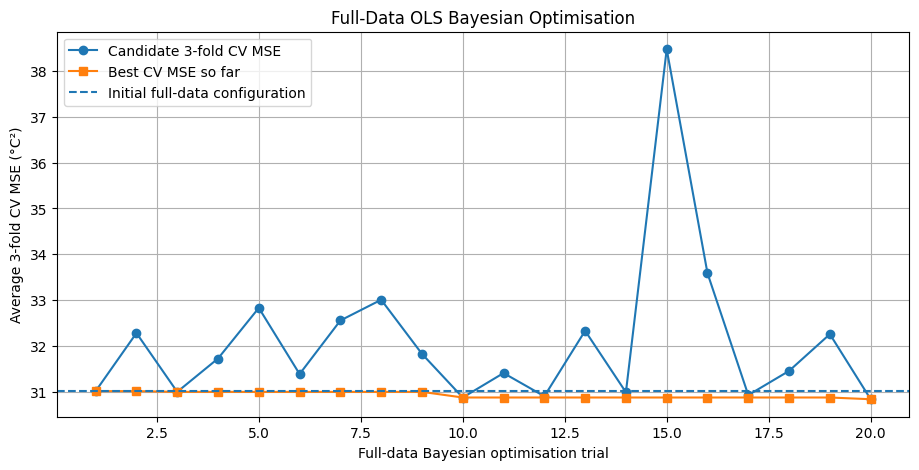

,Configuration,s1,s2,s3,s4,CV MSE
0,Initial,89,265,622,3829,31.0167
1,Best full-data,67,97,693,3339,30.8403


Relative MSE improvement: 0.57%
Mean runtime per evaluation: 16.02 seconds
Total recorded evaluation runtime: 5.34 minutes
Minimum numerical rank: 109


In [46]:

# STEP 6.3D.6D — Analyse full-data Bayesian results

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load directly from the persistent CSV
history = pd.read_csv(RESULTS_PATH)

history = history.sort_values("trial").copy()

history["best_so_far"] = (
    history["mean_cv_mse"].cummin()
)

# Plot Bayesian optimisation history
plt.figure(figsize=(11, 5))

plt.plot(
    history["trial"],
    history["mean_cv_mse"],
    "o-",
    label="Candidate 3-fold CV MSE"
)

plt.plot(
    history["trial"],
    history["best_so_far"],
    "s-",
    label="Best CV MSE so far"
)

plt.axhline(
    history.iloc[0]["mean_cv_mse"],
    linestyle="--",
    label="Initial full-data configuration"
)

plt.xlabel("Full-data Bayesian optimisation trial")
plt.ylabel("Average 3-fold CV MSE (°C²)")
plt.title("Full-Data OLS Bayesian Optimisation")
plt.legend()
plt.grid(True)
plt.show()


# Compare initial and final configurations
best = history.loc[
    history["mean_cv_mse"].idxmin()
]

initial_mse = float(
    history.iloc[0]["mean_cv_mse"]
)

best_mse = float(best["mean_cv_mse"])

improvement = (
    (initial_mse - best_mse) / initial_mse
) * 100

comparison = pd.DataFrame([
    {
        "Configuration": "Initial",
        "s1": int(history.iloc[0]["s1"]),
        "s2": int(history.iloc[0]["s2"]),
        "s3": int(history.iloc[0]["s3"]),
        "s4": int(history.iloc[0]["s4"]),
        "CV MSE": initial_mse
    },
    {
        "Configuration": "Best full-data",
        "s1": int(best["s1"]),
        "s2": int(best["s2"]),
        "s3": int(best["s3"]),
        "s4": int(best["s4"]),
        "CV MSE": best_mse
    }
])

display(comparison.round(4))

print(f"Relative MSE improvement: {improvement:.2f}%")

print(
    "Mean runtime per evaluation:",
    round(history["total_time_s"].mean(), 2),
    "seconds"
)

print(
    "Total recorded evaluation runtime:",
    round(history["total_time_s"].sum() / 60, 2),
    "minutes"
)

print(
    "Minimum numerical rank:",
    history["min_numerical_rank"].min()
)


### 4.9.10 Model-Specific Computational Budgets and Larger-Scale Validation (Step 6.3D.7A)

For the five remaining regression models, full-million-row Bayesian optimisation had not been demonstrated feasible. A larger but resource-limited sampling strategy was therefore adopted. The fixed SVR scalability tests motivated using **320 training observations per profile** for SVR, while **640 training observations per profile** were selected for k-NN, Random Forest, Extra Trees and MLP. Every algorithm was evaluated on the same **640 selected observations per validation profile** across the original three grouped folds, with all temporal features calculated from the underlying complete 2 Hz recording histories before sampling.

This produced a common validation design but different training budgets: across all 55 profiles, the training sampling pools contained 17,600 selected observations for SVR and 35,200 for the other four models, before splitting each fold into training and validation profiles. Standardisation remained training-fold-only. For MLP, the training procedure was changed from the early pilot by increasing `max_iter` from 200 to 400 and enabling early stopping with a 10% internal training-fold validation fraction. These changes aimed to address earlier convergence warnings, but they also mean the larger-scale MLP setup is not strictly identical to the pilot setup.

In [47]:

# STEP 6.3D.7A — Larger-scale model evaluation

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.exceptions import ConvergenceWarning

# Model-specific sample sizes
TRAIN_SAMPLES = {
    "SVR": 320,
    "k-NN": 640,
    "Random Forest": 640,
    "Extra Trees": 640,
    "MLP": 640
}

VALIDATION_SAMPLES = 640

# Existing development-profile fold assignments
fold_lookup = (
    profile_cv.set_index("profile_id")["cv_fold"]
    .astype(int)
    .to_dict()
)

assert len(train_df) == 1055198
assert len(fold_lookup) == 55

for function in [
    make_paper_inputs,
    make_temporal_features,
    make_regressor,
    nested_sample_order
]:
    assert callable(function)


def evaluate_larger_model_cv(model_name, parameters):
    """
    Evaluate one Bayesian candidate using:
    - Full original 2-Hz temporal histories
    - Nested training samples
    - Fixed 640-sample/profile validation
    - Three profile-grouped CV folds
    """

    start_total = time.perf_counter()

    n_train = TRAIN_SAMPLES[model_name]
    n_val = VALIDATION_SAMPLES
    n_select = max(n_train, n_val)

    spans = decode_spans(parameters[:4])

    hp = {
        dimension.name: value
        for dimension, value in zip(
            MODEL_SPACES[model_name],
            parameters[4:]
        )
    }

    # ==========================================
    # A — Build the temporal features
    # ==========================================

    feature_arrays = []
    target_arrays = []
    profile_arrays = []
    rank_arrays = []

    for pid, profile in train_df.groupby(
        "profile_id", sort=False
    ):

        # Nested sample order is independent of
        # the particular smoothing spans.
        order = nested_sample_order(
            len(profile), n_select
        )

        positions = np.sort(
            np.asarray(order, dtype=int)
        )

        rank_lookup = {
            int(position): rank
            for rank, position in enumerate(order)
        }

        ranks = np.asarray([
            rank_lookup[int(position)]
            for position in positions
        ])

        X_original = make_paper_inputs(profile)

        # Calculate EWMA/EWMS using all 2-Hz observations
        X_full = make_temporal_features(
            X_original,
            profile["profile_id"],
            spans
        )

        X_selected = X_full.iloc[
            positions
        ].to_numpy(dtype=np.float64)

        y_selected = profile["pm"].iloc[
            positions
        ].to_numpy(dtype=np.float64)

        feature_arrays.append(X_selected)
        target_arrays.append(y_selected)

        profile_arrays.append(
            np.full(len(positions), int(pid))
        )

        rank_arrays.append(ranks)

    X = np.vstack(feature_arrays)
    y = np.concatenate(target_arrays)
    profile_ids = np.concatenate(profile_arrays)
    sample_ranks = np.concatenate(rank_arrays)

    feature_time = time.perf_counter() - start_total

    assert X.shape[1] == 108
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    fold_ids = pd.Series(
        profile_ids
    ).map(fold_lookup).to_numpy(dtype=int)

    # ==========================================
    # B — Train and evaluate on all three folds
    # ==========================================

    fold_scores = []
    convergence_warnings = 0
    training_time = 0.0
    inference_time = 0.0

    for fold in [1, 2, 3]:

        train_mask = (
            (fold_ids != fold)
            & (sample_ranks < n_train)
        )

        val_mask = (
            (fold_ids == fold)
            & (sample_ranks < n_val)
        )

        assert set(
            profile_ids[train_mask]
        ).isdisjoint(
            set(profile_ids[val_mask])
        )

        estimator = make_regressor(
            model_name, hp
        )

        # Revised MLP training procedure:
        # early stopping uses training-fold data only.
        if model_name == "MLP":
            estimator.max_iter = 400
            estimator.early_stopping = True
            estimator.validation_fraction = 0.10
            estimator.n_iter_no_change = 15

        pipeline = TransformedTargetRegressor(
            regressor=Pipeline([
                ("scaler", StandardScaler()),
                ("model", estimator)
            ]),
            transformer=StandardScaler()
        )

        start_fit = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter(
                "always", ConvergenceWarning
            )

            pipeline.fit(
                X[train_mask],
                y[train_mask]
            )

        training_time += (
            time.perf_counter() - start_fit
        )

        convergence_warnings += sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        start_predict = time.perf_counter()

        predictions = pipeline.predict(
            X[val_mask]
        )

        inference_time += (
            time.perf_counter() - start_predict
        )

        assert np.isfinite(predictions).all()

        fold_scores.append(
            float(mean_squared_error(
                y[val_mask],
                predictions
            ))
        )

    mean_mse = float(np.mean(fold_scores))

    return {
        "spans": spans,
        "hyperparameters": hp,
        "fold_scores": fold_scores,
        "mean_cv_mse": mean_mse,
        "feature_time_s": feature_time,
        "training_time_s": training_time,
        "inference_time_s": inference_time,
        "total_time_s": time.perf_counter() - start_total,
        "convergence_warnings": convergence_warnings
    }


print("PASS: Larger-scale CV objective defined")


PASS: Larger-scale CV objective defined


### 4.9.11 Larger-Scale Bayesian Hyperparameter Search (Step 6.3D.7B)

An automated larger-scale Bayesian search was performed sequentially for SVR, k-NN, Random Forest, Extra Trees and MLP. **Twelve configurations per model** were evaluated: Trial 1 reevaluated that model's best eight-trial pilot hyperparameters under the *new* sampling and validation protocol, and the following 11 configurations were generated by Gaussian-process Bayesian optimisation. Previous pilot MSE values were deliberately not reused as objective scores. The workflow therefore performed **60 three-fold evaluations or 180 fold-level model fits** and saved each model's result table in `scaled_model_bayesian/`.

The search executed automatically without needing to manually choose or rerun each model. All five searches completed, and their output tables were checked for finite, internally consistent fold-mean scores. **No convergence warnings were recorded** during the larger-scale runs, including for the revised MLP implementation. The measured runtime varied strongly among algorithms, reflecting differences in model complexity, selected hyperparameters and training sample size.

In [48]:
# STEP 6.3D.7B — Automatic large-sample Bayesian optimisation (five models)
# Fresh Run All: start from the freshly produced 6.3C pilot CSVs.
# No checkpoint files, no Google Drive login, no per-model manual action.
import os
import json
import time
import numpy as np
import pandas as pd
from skopt import Optimizer

SEARCH_DIR = str(BASE_DIR / "scaled_model_bayesian")
os.makedirs(SEARCH_DIR, exist_ok=True)
MODEL_ORDER = ["SVR", "k-NN", "Random Forest", "Extra Trees", "MLP"]
SCALED_TRIALS = 12  # each includes a newly scored pilot seed


def json_safe(values):
    """Return native Python values accepted by JSON and scikit-optimize."""
    return [v.item() if isinstance(v, np.generic) else v for v in values]


def run_scaled_bayesian(model_name, n_trials=SCALED_TRIALS):
    """Optimise one model with three profile-grouped CV folds from scratch.

    Previous pilot hyperparameters are used only as a starting configuration;
    their old pilot MSE is *not* reused. Saves a CSV on completion.
    """
    assert model_name in MODEL_ORDER
    basename = model_name.lower().replace(" ", "_").replace("-", "")
    old_path = os.path.join(OUTPUT_DIR, f"{basename}_trials.csv")
    previous = pd.read_csv(old_path)
    assert len(previous) == 8, f"Missing pilot results for {model_name}"
    pilot_best = previous.loc[previous["mean_cv_mse"].idxmin()]
    seed = json_safe(json.loads(pilot_best["parameters_json"]))

    model_optimizer = Optimizer(
        dimensions=SPAN_SPACE + MODEL_SPACES[model_name],
        base_estimator="GP", acq_func="EI", acq_optimizer="sampling",
        n_initial_points=5, random_state=42
    )
    trials = []
    for number in range(1, n_trials + 1):
        parameters = seed if number == 1 else json_safe(model_optimizer.ask())
        start = time.perf_counter()
        evaluation = evaluate_larger_model_cv(model_name, parameters)
        score = float(evaluation["mean_cv_mse"])
        assert np.isfinite(score)
        model_optimizer.tell(parameters, score)

        record = {
            "trial": number,
            "source": "Reevaluated pilot seed" if number == 1 else "Bayesian proposal",
            "parameters_json": json.dumps(parameters),
            "hyperparameters_json": json.dumps(evaluation["hyperparameters"],
                                                default=lambda x: x.item()),
            "s1": evaluation["spans"][0], "s2": evaluation["spans"][1],
            "s3": evaluation["spans"][2], "s4": evaluation["spans"][3],
            "fold1_mse": evaluation["fold_scores"][0],
            "fold2_mse": evaluation["fold_scores"][1],
            "fold3_mse": evaluation["fold_scores"][2],
            "mean_cv_mse": score,
            "feature_time_s": evaluation["feature_time_s"],
            "training_time_s": evaluation["training_time_s"],
            "inference_time_s": evaluation["inference_time_s"],
            "total_time_s": evaluation["total_time_s"],
            "convergence_warnings": evaluation["convergence_warnings"]
        }
        trials.append(record)
        print(f"{model_name} — {number}/{n_trials}, CV MSE={score:.4f}, "
              f"runtime={record['total_time_s']:.1f}s", flush=True)

    result = pd.DataFrame(trials)
    path = os.path.join(SEARCH_DIR, f"{basename}_trials.csv")
    result.to_csv(path, index=False)
    return result

# Completely unattended sequential execution
scaled_results = {}
for number, model_name in enumerate(MODEL_ORDER, 1):
    print(f"\n{'='*50}\nMODEL {number}/5 — {model_name}\n{'='*50}", flush=True)
    scaled_results[model_name] = run_scaled_bayesian(model_name, SCALED_TRIALS)
    print(f"PASS: {model_name} large-sample optimisation complete", flush=True)

print("PASS: All five larger-scale searches completed")



MODEL 1/5 — SVR
SVR — 1/12, CV MSE=36.0818, runtime=17.5s
SVR — 2/12, CV MSE=40.1421, runtime=78.6s
SVR — 3/12, CV MSE=137.4819, runtime=75.2s
SVR — 4/12, CV MSE=36.2789, runtime=76.8s
SVR — 5/12, CV MSE=39.1984, runtime=116.2s
SVR — 6/12, CV MSE=38.0090, runtime=25.4s
SVR — 7/12, CV MSE=37.4536, runtime=14.6s
SVR — 8/12, CV MSE=35.6367, runtime=39.7s
SVR — 9/12, CV MSE=48.6276, runtime=53.3s
SVR — 10/12, CV MSE=36.9187, runtime=131.4s
SVR — 11/12, CV MSE=36.2921, runtime=64.3s
SVR — 12/12, CV MSE=36.8667, runtime=31.7s
PASS: SVR large-sample optimisation complete

MODEL 2/5 — k-NN
k-NN — 1/12, CV MSE=75.8004, runtime=14.3s
k-NN — 2/12, CV MSE=77.3986, runtime=18.1s
k-NN — 3/12, CV MSE=75.2321, runtime=14.6s
k-NN — 4/12, CV MSE=80.3162, runtime=19.3s
k-NN — 5/12, CV MSE=99.1525, runtime=21.7s
k-NN — 6/12, CV MSE=87.9293, runtime=17.7s
k-NN — 7/12, CV MSE=81.6895, runtime=22.1s
k-NN — 8/12, CV MSE=78.0540, runtime=14.2s
k-NN — 9/12, CV MSE=95.7732, runtime=14.2s
k-NN — 10/12, CV MSE=71

**Reproducibility note.** Numerical results and interpretations written earlier in this notebook describe a previous completed run. When using **Run all**, rely on newly generated output tables for the current measurements. Differences in library versions, timing, and fresh Bayesian proposals may change the numerical results. The notebook stops at Step 6.3D.7; final full-development retraining (Step 6.4) and untouched test-set evaluation (Step 7) are not yet implemented.

### 4.9.12 Comparison of Larger-Scale Bayesian Optimisation Results (Step 6.3D.7C)

| Model | Training samples/profile | Trials | Best mean CV MSE (°C²) | Best four spans | Total search time (min) |
|---|---:|---:|---:|---|---:|
| **MLP** | 640 | 12 | **33.1719** | (52, 407, 647, 6467) | 15.7959 |
| SVR | 320 | 12 | 35.6367 | (91, 358, 1712, 7591) | 12.0783 |
| Random Forest | 640 | 12 | 48.6403 | (99, 152, 1640, 7415) | 9.0087 |
| Extra Trees | 640 | 12 | 49.5461 | (46, 182, 620, 4544) | 1.8280 |
| k-NN | 640 | 12 | 70.9823 | (89, 96, 1252, 7227) | 3.4467 |

Among the five resource-limited larger-scale searches, **MLP achieved the lowest mean cross-validation MSE**, followed by SVR. All recorded convergence-warning totals were zero. Extra Trees had the shortest total Bayesian-search runtime in this execution, whereas MLP required the longest. These timing differences describe the particular Colab environment, search configurations and training budgets, rather than invariant model properties.

The already optimised OLS model achieved a lower numerical development-stage MSE of **30.8403 °C²**, but it was evaluated using *all* development observations, unlike these five models. Consequently, the OLS score and the sampled-model scores must **not** be treated as a controlled six-model ranking. Even among the five sampled models, SVR had fewer training observations, and 12 evaluations remain a limited hyperparameter search. These results are therefore best interpreted as candidate models and computational feasibility evidence, not final generalisation performance.

**Conclusion and transition.** From Steps 6.3A through 6.3D.7C, the project progressed from validating Bayesian span selection on a 4,400-observation OLS pilot to implementing six model-family searches, examining SVR scalability with nested grouped validation, verifying a QR-compressed full-data OLS method, completing 20 full-data OLS evaluations and completing 60 larger-scale evaluations for the other five models. The next planned stage is **Step 6.3D.8**, assessing which estimators can feasibly be trained on all 1,055,198 development observations, followed by **Step 6.4**, fitting the selected final models, and **Step 7**, evaluating them once on the untouched 14-profile test partition. The independent reduced-sampling-frequency investigation begins after the 2 Hz benchmark is established.

In [49]:
# STEP 6.3D.7C — Automatically consolidate completed model results
rows = []
for model_name in MODEL_ORDER:
    trials = scaled_results[model_name]
    assert len(trials) == SCALED_TRIALS
    folds = trials[["fold1_mse", "fold2_mse", "fold3_mse"]]
    np.testing.assert_allclose(folds.mean(axis=1), trials["mean_cv_mse"])
    b = trials.loc[trials["mean_cv_mse"].idxmin()]
    rows.append({
        "Model": model_name,
        "Training samples/profile": TRAIN_SAMPLES[model_name],
        "Evaluations": len(trials),
        "Best CV MSE": b["mean_cv_mse"],
        "Span 1": int(b["s1"]), "Span 2": int(b["s2"]),
        "Span 3": int(b["s3"]), "Span 4": int(b["s4"]),
        "Total runtime (min)": trials["total_time_s"].sum() / 60,
        "Convergence warnings": int(trials["convergence_warnings"].sum())
    })
scaled_summary = pd.DataFrame(rows).sort_values("Best CV MSE")
scaled_summary.to_csv(os.path.join(SEARCH_DIR, "larger_scale_model_summary.csv"), index=False)
print("PASS: all five model searches and consistency checks completed")
display(scaled_summary.round(4))
print("Notes: OLS used all development observations; the other five models used")
print("nested subsamples. These CV results are NOT the final held-out 2 Hz test benchmark.")


PASS: all five model searches and consistency checks completed


,Model,Training samples/profile,Evaluations,Best CV MSE,Span 1,Span 2,Span 3,Span 4,Total runtime (min),Convergence warnings
4,MLP,640,12,33.1719,52,407,647,6467,15.7959,0
0,SVR,320,12,35.6367,91,358,1712,7591,12.0783,0
2,Random Forest,640,12,48.6403,99,152,1640,7415,9.0087,0
3,Extra Trees,640,12,49.5461,46,182,620,4544,1.8280,0
1,k-NN,640,12,70.9823,89,96,1252,7227,3.4467,0


Notes: OLS used all development observations; the other five models used
nested subsamples. These CV results are NOT the final held-out 2 Hz test benchmark.
